# CNN-Based Image Feature Extraction
### From hand-designed features to *learned* features

**Course:** Feature Engineering & MLOps · BTech Semester VII  
**Runs on:** a normal laptop CPU (no GPU, no paid service, no API key). Total run time: about 2–4 minutes.

---

## The one idea to remember

> **Traditional computer vision:** *we* design (or choose) the feature-extraction rules.  
> **CNN-based feature learning:** *training* adjusts the network's parameters so that it discovers features that are useful for the task.  
> The resulting **CNN feature vector** can then be given to a classifier or any other downstream system.

A CNN does **not** "understand" pictures the way a person does. It is a function with many adjustable numbers (parameters). Training nudges those numbers, using examples and a loss function, until the function produces representations that help with the task.

## What you will be able to do after this notebook

1. Explain how an image is stored as numbers and why raw pixels are an awkward input for a classic ML model.
2. Explain HOG as a *hand-designed* feature extractor and compute it.
3. Explain **filter, convolution, feature map, ReLU, pooling** and calculate a convolution by hand.
4. Explain, in plain words, how a CNN *learns* its filters (loss → backpropagation → optimizer).
5. Train a small CNN, look at its filters and feature maps, and say what you can and **cannot** conclude from them.
6. Turn a trained CNN into a **feature extractor** (a numeric vector per image) and feed it to scikit-learn.
7. Compare handcrafted and learned features honestly, using measured results.

## How to read this notebook

Every part follows the same rhythm: **Intuition → Visual example → Simple explanation → Code → Output → Interpretation → Real-world use.**

Two tags keep us honest about what is *evidence* and what is *story*:

* **[OBSERVED]** – something the code in this notebook actually computed or plotted.
* **[INTUITION]** – a helpful mental picture. It may be a simplification and is not proof.

| Part | Topic |
|---|---|
| 1 | What is image feature extraction? Pixels as numbers |
| 2 | Traditional features: HOG |
| 3 | What is a CNN? Filters, convolution, feature maps, ReLU, pooling |
| 4 | How does a CNN *learn* edges, textures and shapes? |
| 5 | Train a small CNN; look at filters and feature maps |
| 6 | CNN features as a **feature vector** → scikit-learn |
| 7 | Handcrafted vs CNN features |
| 8 | Industry use cases |
| 9 | Exercises (solutions are at the end) |
| 10 | Summary, knowledge check, and the MLOps connection |

## 0. Setup

### Installation (only if something is missing)

You need Python 3.9+ and these libraries. **Do not reinstall or upgrade packages you already have** — first run the next code cell; it tells you what is missing.

```bash
# pip
pip install numpy matplotlib scikit-learn scikit-image tensorflow

# or conda
conda install numpy matplotlib scikit-learn scikit-image
pip install tensorflow          # (TensorFlow is usually installed with pip even in conda)
```

* TensorFlow's **CPU** version is enough (`pip install tensorflow` works on CPU). On a machine without internet access, install packages beforehand.
* The notebook downloads one small public dataset (**Fashion-MNIST**, about 30 MB) the first time it runs. If the download fails, you will see a clear message (see Part 1).

### The imports

In [1]:
import os, sys, time, gzip, urllib.request, tempfile
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # keep TensorFlow's start-up chatter out of the notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

from skimage.feature import hog
from skimage.draw import disk
from skimage.filters import gaussian
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except ImportError as err:
    raise ImportError(
        "TensorFlow is not installed in this Python environment.\n"
        "Install it with:  pip install tensorflow\n"
        "then restart the kernel and run this cell again."
    ) from err

SEED = 42
tf.get_logger().setLevel("ERROR")      # hide harmless TensorFlow retracing warnings
keras.utils.set_random_seed(SEED)      # seeds Python, NumPy and TensorFlow together
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("GPUs visible to TensorFlow:", len(tf.config.list_physical_devices("GPU")), "(not needed - this notebook is CPU-friendly)")

I0000 00:00:1792176451.668869   11916 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.13.16 | NumPy 2.5.3 | TensorFlow 2.21.0 | Keras 3.15.1
GPUs visible to TensorFlow: 0 (not needed - this notebook is CPU-friendly)


I0000 00:00:1792176452.980616   11916 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


**Output check.** You should see version numbers and no error. A grey TensorFlow/oneDNN info message about "custom operations" is normal and harmless. If you see `ImportError`, follow the message, restart the kernel, and re-run.

> **Reproducibility note.** We fix random seeds, so you should get results that are *very close* to ours. Small differences (a fraction of a percent) are normal across TensorFlow versions and CPUs. Our numbers in the text are always *measured in the cells above them*; when you re-run, trust your own outputs.

### A small plotting style (so every figure is readable)

In [2]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"      # colour-blind-safe pair + a neutral grey

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,   # less ink, more data
    "axes.grid": False, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.titleweight": "bold", "font.size": 10,
})

def show_image(ax, img, title="", cmap="gray", vmin=None, vmax=None):
    """Draw one image without axis ticks (images do not need them)."""
    ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

def annotate_cells(ax, matrix, fmt="{:.0f}", color_switch=None, fontsize=8, abs_switch=None):
    """Write each number on top of its cell. White text on dark cells, black on light cells.
    For sequential colour maps pass nothing (we split at the middle value); for diverging maps
    (dark at both ends) pass abs_switch: values with |v| above it get white text."""
    lo, hi = np.nanmin(matrix), np.nanmax(matrix)
    mid = (lo + hi) / 2 if color_switch is None else color_switch
    for (r, c), v in np.ndenumerate(matrix):
        dark = abs(v) > abs_switch if abs_switch is not None else v < mid
        ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=fontsize, color="white" if dark else "black")
print("Helpers ready.")

Helpers ready.


---
# Part 1 · What is image feature extraction?

## Intuition
A photo of a cat is just a **grid of numbers** to a computer. A machine-learning model cannot "look" at it. It needs a **numerical representation** — a list of numbers — that makes the difference between *cat* and *dog* easy to see.

Turning an image into such a list of useful numbers is called **image feature extraction**. There are three broad ways to get the numbers:

| | **Raw pixels** | **Handcrafted features** | **Learned features** |
|---|---|---|---|
| **What it is** | Every pixel value, as is | Numbers from a recipe that a human designed (e.g. HOG, SIFT) | Numbers produced by a model whose parameters were learned from data (e.g. a CNN) |
| **Who decides the recipe?** | Nobody (no processing) | The engineer | The training process (guided by data, loss function, architecture) |
| **Example** | 28×28 image → 784 numbers | Edge-orientation histograms | Output of a CNN's convolutional layers |
| **Needs training data to build the features?** | No | No (only the classifier needs it) | **Yes** |
| **Typical weakness** | Moving an object a little changes *many* numbers | Recipe may miss what matters for *your* task | Needs data and compute; harder to interpret |

We will use all three on the same pictures and **measure** how they compare.

## The dataset: Fashion-MNIST
Small grayscale pictures (28×28 pixels) of **10 kinds of clothing**: T-shirt, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot. It is a standard teaching dataset: small enough for a laptop, and the classes look different enough to reason about.
(We do not use cats and dogs in the code because those photos are large colour images and need much longer training. The *ideas* are identical.)

The next cell loads it. It tries the normal Keras download first, then a public GitHub copy. If both fail it stops with a clear message — it never substitutes fake data.

In [3]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

MIRROR = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz",  "t10k-labels-idx1-ubyte.gz"]

def _read_idx(path, is_image):
    """Read the simple IDX file format used by MNIST-style datasets (16-byte header for images, 8 for labels)."""
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16 if is_image else 8)
    return data.reshape(-1, 28, 28) if is_image else data

def load_fashion_mnist():
    """Return (x_train, y_train), (x_test, y_test) as uint8 arrays. Real data only."""
    try:
        return keras.datasets.fashion_mnist.load_data()                    # 1st choice: the usual Keras download
    except Exception as err:                                               # noqa: BLE001 - we want to report any failure
        print(f"Keras download failed ({type(err).__name__}). Trying the GitHub copy of the same dataset...")
    cache = os.path.join(tempfile.gettempdir(), "fashion_mnist_mirror")
    os.makedirs(cache, exist_ok=True)
    try:
        for name in FILES:
            target = os.path.join(cache, name)
            if not os.path.exists(target):
                urllib.request.urlretrieve(MIRROR + name, target)
        return ((_read_idx(os.path.join(cache, FILES[0]), True),  _read_idx(os.path.join(cache, FILES[1]), False)),
                (_read_idx(os.path.join(cache, FILES[2]), True),  _read_idx(os.path.join(cache, FILES[3]), False)))
    except Exception as err:                                               # noqa: BLE001
        raise RuntimeError(
            "Could not download Fashion-MNIST (no internet, or the site is blocked).\n"
            "What you can do:\n"
            "  1. Connect to the internet and re-run this cell, or\n"
            "  2. Download the 4 files listed in FILES from " + MIRROR + "\n"
            f"     into the folder {cache} and re-run this cell.\n"
            "This notebook needs the real dataset; it will not continue with made-up data."
        ) from err

(x_train_all, y_train_all), (x_test, y_test) = load_fashion_mnist()
print("Training pool :", x_train_all.shape, y_train_all.shape, "dtype:", x_train_all.dtype)
print("Test set      :", x_test.shape, y_test.shape)
print("Pixel value range:", x_train_all.min(), "to", x_train_all.max(), "(0 = black, 255 = white)")

Training pool : (60000, 28, 28) (60000,) dtype: uint8
Test set      : (10000, 28, 28) (10000,)
Pixel value range: 0 to 255 (0 = black, 255 = white)


**Interpretation [OBSERVED].** The training pool has 60,000 pictures, the test set 10,000. Each picture is a 28×28 grid; each cell holds a whole number from 0 (black) to 255 (white).

**Scaling.** Models train more smoothly when inputs are small numbers, so we divide by 255 to get values between 0 and 1.

### How we split the data (important — this avoids a classic leakage mistake)

| Subset | Size | Used for |
|---|---|---|
| `x_cnn` | first 30,000 training images | **training the CNN** |
| `x_clf` | next 5,000 training images (never seen by the CNN) | training the *downstream classifier* (logistic regression) on top of any feature type |
| `x_test` | the 10,000 test images | final scores for **every** method; never used for training or tuning |

Using the same untouched test set for all methods makes the comparison fair.

CNN training set       : (30000, 28, 28)
Classifier training set: (5000, 28, 28)
Test set               : (10000, 28, 28)


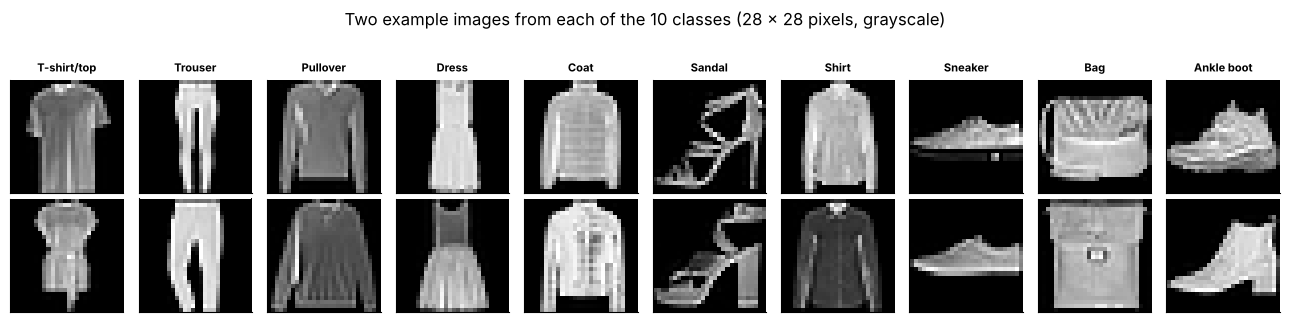

In [4]:
x_train_all = x_train_all.astype("float32") / 255.0
x_test      = x_test.astype("float32") / 255.0

x_cnn, y_cnn = x_train_all[:30000],      y_train_all[:30000]
x_clf, y_clf = x_train_all[30000:35000], y_train_all[30000:35000]

print("CNN training set       :", x_cnn.shape)
print("Classifier training set:", x_clf.shape)
print("Test set               :", x_test.shape)

fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for k in range(10):
    first = np.where(y_clf == k)[0][0]            # first example of class k
    second = np.where(y_clf == k)[0][1]
    show_image(axes[0, k], x_clf[first], CLASS_NAMES[k])
    show_image(axes[1, k], x_clf[second])
    axes[0, k].title.set_fontsize(8)
fig.suptitle("Two example images from each of the 10 classes (28 x 28 pixels, grayscale)", y=1.02)
plt.tight_layout(); plt.show()

## An image is a matrix of numbers
Below: one image, and a zoomed-in 8×8 patch with the actual pixel values written on top. This is *all* the computer sees.

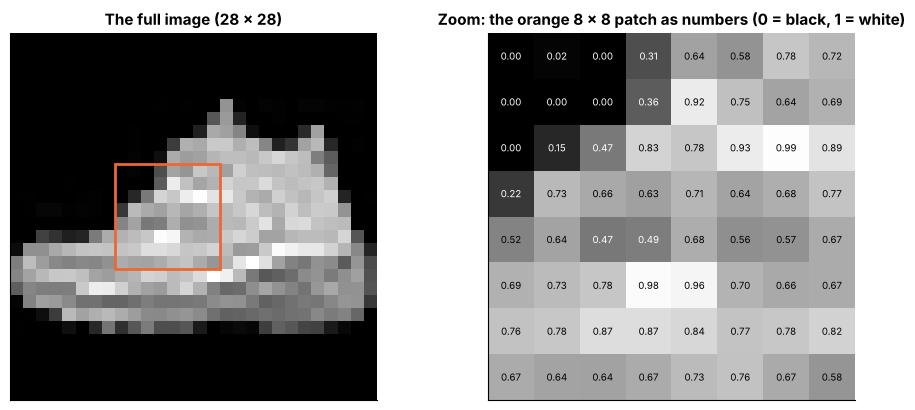

Shape of one image: (28, 28)  -> as a flat vector: (784,)


In [5]:
img = x_clf[np.where(y_clf == 9)[0][0]]               # an ankle boot
r0, c0 = 10, 8                                        # top-left corner of the zoomed patch
patch = img[r0:r0+8, c0:c0+8]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
show_image(axes[0], img, f"The full image ({img.shape[0]} x {img.shape[1]})")
axes[0].add_patch(plt.Rectangle((c0-0.5, r0-0.5), 8, 8, fill=False, edgecolor=ORANGE, linewidth=2))
axes[1].imshow(patch, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
annotate_cells(axes[1], patch, fmt="{:.2f}", color_switch=0.5, fontsize=7)
axes[1].set_title("Zoom: the orange 8 x 8 patch as numbers (0 = black, 1 = white)")
axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout(); plt.show()

print("Shape of one image:", img.shape, " -> as a flat vector:", img.reshape(-1).shape)

**Interpretation [OBSERVED].** The ankle boot is nothing but a 28×28 table of numbers. The flat version used by a classic ML model has **784** numbers (28 × 28) with no information about which numbers were neighbours.

## Why raw pixels are not always convenient
Two problems, shown with real numbers:

1. **Position sensitivity.** If the same boot moves 3 pixels to the right, almost every pixel value changes, so the 784-number vector changes a lot — even though a human sees "the same boot".
2. **No structure.** The model gets 784 independent columns. It is not told that pixel (10, 8) sits next to pixel (10, 9), or that edges and shapes matter.

Let us measure the first problem. We compare, for 300 random images: the distance between an image and **itself shifted 3 pixels**, versus the distance to **a different image of the same class**, versus **an image of a different class**. (Distance = Euclidean distance between the 784-number vectors; smaller = "more similar" to the model.)

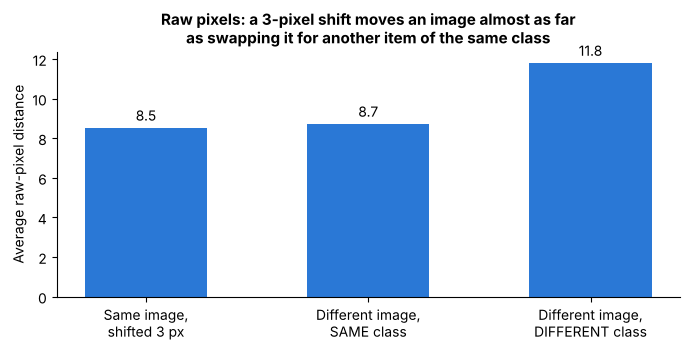

Average distance - shifted self: 8.51 | other image, same class: 8.71 | other class: 11.78


In [6]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(x_clf), size=300, replace=False)

d_shifted, d_same, d_other = [], [], []
for i in sample_ids:
    a = x_clf[i]
    shifted = np.roll(a, 3, axis=1)                                   # move the picture 3 pixels to the right (edges are black, so nothing is lost)
    d_shifted.append(np.linalg.norm(a - shifted))
    j_same  = rng.choice(np.where(y_clf == y_clf[i])[0]);  d_same.append(np.linalg.norm(a - x_clf[j_same]))
    j_other = rng.choice(np.where(y_clf != y_clf[i])[0]);  d_other.append(np.linalg.norm(a - x_clf[j_other]))

means = [np.mean(d_shifted), np.mean(d_same), np.mean(d_other)]
labels = ["Same image,\nshifted 3 px", "Different image,\nSAME class", "Different image,\nDIFFERENT class"]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, means, color=BLUE, width=0.55)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylabel("Average raw-pixel distance")
ax.set_title("Raw pixels: a 3-pixel shift moves an image almost as far\nas swapping it for another item of the same class")
plt.tight_layout(); plt.show()
print(f"Average distance - shifted self: {means[0]:.2f} | other image, same class: {means[1]:.2f} | other class: {means[2]:.2f}")

**Interpretation [OBSERVED].** In raw-pixel space, the *same* item shifted by only 3 pixels looks nearly as "different" to a distance-based method as a *different* item of the same class. That is the practical weakness of raw pixels: they describe *where* ink is, not *what shape* it forms.

## Baseline: raw pixels → Logistic Regression
Before using smarter features, we always measure a **baseline**. Here: flatten each image into 784 numbers, standardise, and train scikit-learn's Logistic Regression on the 5,000 classifier-training images. Then score on the 10,000 test images.

* `StandardScaler` rescales each column to mean 0 and spread 1 (many linear models train better this way).
* `make_pipeline` chains scaler → classifier, so the same scaling is applied to the test data. (Fitting the scaler on training data only is how we avoid **leakage** from the test set.)

In [7]:
def fit_and_score(features_train, features_test, y_train=None, y_test_=None, max_iter=2000):
    """Train scaler + logistic regression on one feature type; return (test accuracy, fitted pipeline, seconds)."""
    y_train = y_clf if y_train is None else y_train
    y_test_ = y_test if y_test_ is None else y_test_
    t0 = time.time()
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=max_iter))
    model.fit(features_train, y_train)
    return model.score(features_test, y_test_), model, time.time() - t0

raw_train = x_clf.reshape(len(x_clf), -1)        # (5000, 784)
raw_test  = x_test.reshape(len(x_test), -1)      # (10000, 784)
print("Raw feature matrices:", raw_train.shape, raw_test.shape)

acc_raw, _, secs = fit_and_score(raw_train, raw_test)
print(f"Raw pixels + Logistic Regression -> test accuracy = {acc_raw:.3f}  (trained in {secs:.1f} s)")

majority = DummyClassifier(strategy="most_frequent").fit(raw_train, y_clf)
print(f"For scale: always guessing one class -> accuracy = {majority.score(raw_test, y_test):.3f}  (10 balanced classes = 10% by luck)")

Raw feature matrices: (5000, 784) (10000, 784)


Raw pixels + Logistic Regression -> test accuracy = 0.793  (trained in 8.2 s)
For scale: always guessing one class -> accuracy = 0.100  (10 balanced classes = 10% by luck)


**Interpretation [OBSERVED].** Raw pixels already beat guessing by a wide margin, so this is a respectable baseline — raw pixels are not "useless". The question for the rest of the notebook is: *can better features do better with the same classifier and the same amount of classifier-training data?*

**Real-world connection.** In industry you *always* build this kind of simple baseline first. If a fancy feature pipeline cannot beat it by a meaningful margin, it is not worth its complexity (and its maintenance cost in production).

---
# Part 2 · Traditional image feature engineering: HOG

## Intuition
What makes a boot look like a boot and a trouser look like a trouser? A lot of it is **edges** — where the picture changes quickly from dark to bright — and **in which direction** those edges run (vertical sides of a trouser, a sloping toe-cap, the horizontal top of a bag).

**HOG — Histogram of Oriented Gradients** — is a classic *handcrafted* recipe that turns this idea into numbers:

1. **Find local intensity changes.** At each pixel, measure how fast brightness changes (the *gradient*): how big (magnitude) and in which direction.
2. **Estimate the direction of edges.** The gradient direction tells us how an edge is oriented.
3. **Summarise edge orientations in small regions.** Cut the image into small *cells* (e.g. 8×8 pixels). In each cell, count how much "edge strength" points in each of 9 orientation bins (a histogram).
4. **Combine the summaries into one feature vector.** Normalise groups of neighbouring cells (*blocks*) so lighting changes matter less, then concatenate everything.

> **Key point:** a human wrote this recipe. The classifier that comes afterwards (e.g. logistic regression) *learns*, but the feature-extraction steps above are **fixed in advance**.

## Step 1–2: edges and their directions on a simple picture
We draw a synthetic image with a rectangle and a disc, so we know exactly where the edges are.

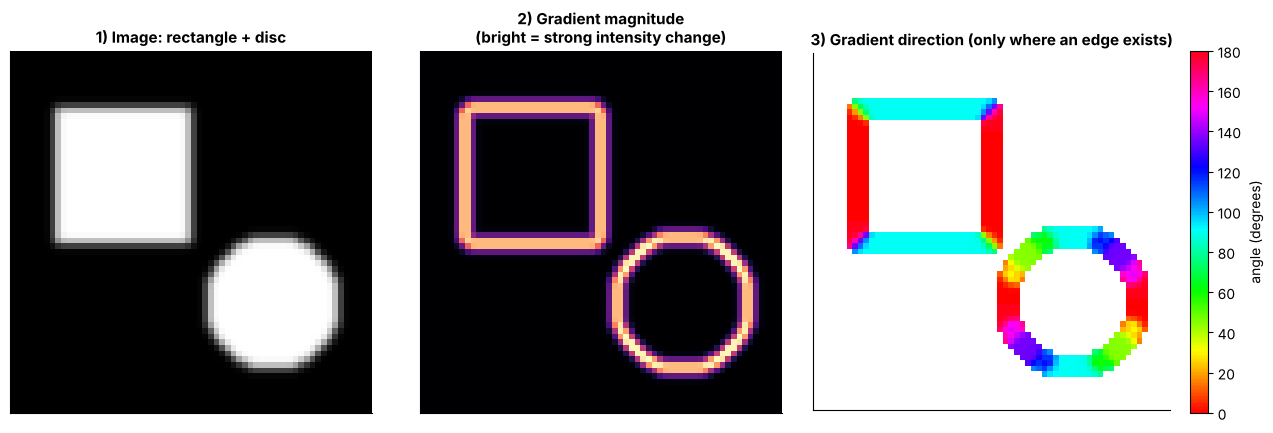

In [8]:
shapes = np.zeros((64, 64))
shapes[10:34, 8:32] = 1.0                       # a bright rectangle (rows 10-33, columns 8-31)
rr, cc = disk((44, 46), 12)                     # a bright disc centred at row 44, column 46, radius 12
shapes[rr, cc] = 1.0
shapes = gaussian(shapes, sigma=0.8)            # slight blur: real edges are never perfectly sharp

gy, gx = np.gradient(shapes)                    # gy: change going DOWN the rows, gx: change going RIGHT along columns
magnitude   = np.hypot(gx, gy)                  # how strong is the change?
orientation = np.degrees(np.arctan2(gy, gx) % np.pi)   # direction of change, folded into 0..180 degrees ("unsigned")

masked = np.ma.masked_where(magnitude < 0.05 * magnitude.max(), orientation)   # hide places with no edge

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
show_image(axes[0], shapes, "1) Image: rectangle + disc")
show_image(axes[1], magnitude, "2) Gradient magnitude\n(bright = strong intensity change)", cmap="magma")
im = axes[2].imshow(masked, cmap="hsv", vmin=0, vmax=180, interpolation="nearest")
axes[2].set_title("3) Gradient direction (only where an edge exists)"); axes[2].set_xticks([]); axes[2].set_yticks([])
cb = fig.colorbar(im, ax=axes[2], fraction=0.046); cb.set_label("angle (degrees)")
plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The magnitude map lights up exactly along the outlines. In the direction map, the *top and bottom* edges of the rectangle share one colour (about 90°: brightness changes up↔down) while its *left and right* edges share another (about 0°: brightness changes left↔right). On the disc, the colour **slides through many angles** as the outline curves.

## Step 3: a histogram of orientations for one small cell
We now take three 8×8 cells, and build the histogram HOG would build: 9 bins of 20° each (0–20, 20–40, …, 160–180), where each pixel adds its **gradient magnitude** to its orientation bin.

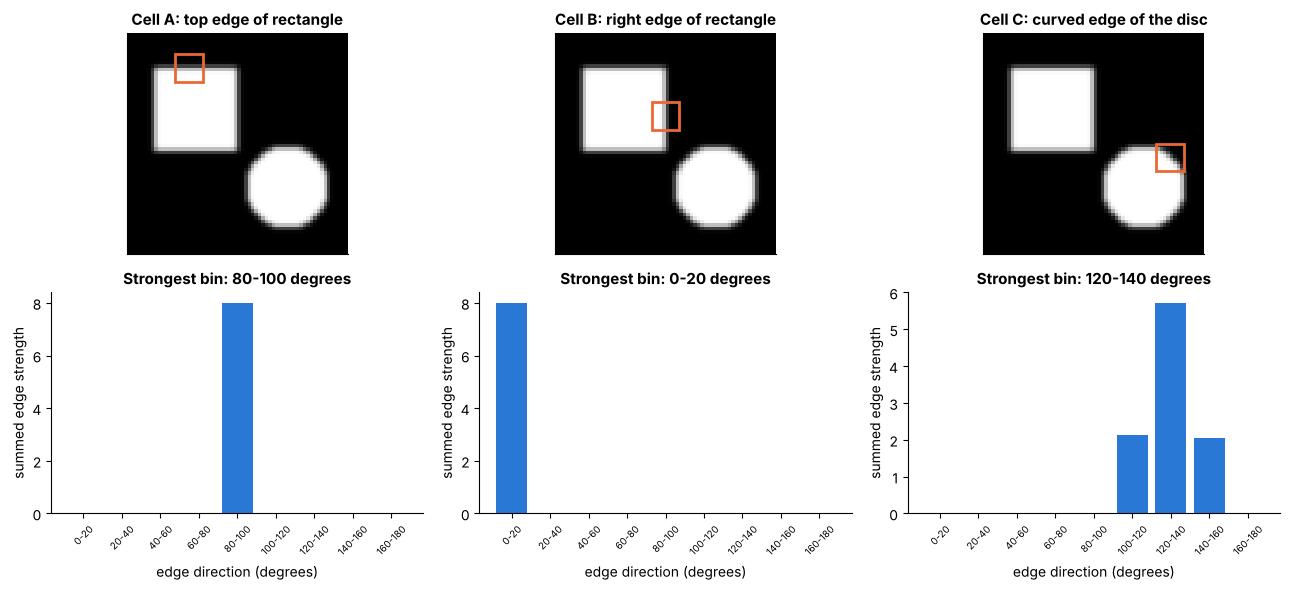

In [9]:
def cell_histogram(r, c, size=8, bins=9):
    """Sum the gradient magnitudes of the cell at (r, c) into `bins` orientation bins covering 0..180 degrees."""
    mags = magnitude[r:r+size, c:c+size].ravel()
    angs = orientation[r:r+size, c:c+size].ravel()
    hist, _ = np.histogram(angs, bins=bins, range=(0, 180), weights=mags)
    return hist

cells = {"Cell A: top edge of rectangle": (6, 14),
         "Cell B: right edge of rectangle": (20, 28),
         "Cell C: curved edge of the disc": (32, 50)}
bin_labels = [f"{b}-{b+20}" for b in range(0, 180, 20)]

fig, axes = plt.subplots(2, 3, figsize=(13, 6), gridspec_kw={"height_ratios": [1, 1]})
for k, (title, (r, c)) in enumerate(cells.items()):
    ax_img = axes[0, k]
    show_image(ax_img, shapes, title)
    ax_img.add_patch(plt.Rectangle((c-0.5, r-0.5), 8, 8, fill=False, edgecolor=ORANGE, linewidth=2))
    h = cell_histogram(r, c)
    axes[1, k].bar(range(9), h, color=BLUE)
    axes[1, k].set_xticks(range(9)); axes[1, k].set_xticklabels(bin_labels, rotation=45, fontsize=7)
    axes[1, k].set_xlabel("edge direction (degrees)"); axes[1, k].set_ylabel("summed edge strength")
    axes[1, k].set_title(f"Strongest bin: {bin_labels[int(np.argmax(h))]} degrees")
plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The cell on the rectangle's top edge puts nearly all its strength into one bin (about 80–100°). The cell on the rectangle's right edge puts it into the first bin (0–20°). The cell on the curved disc edge spreads strength over several neighbouring bins, because the outline's direction changes inside the cell. **That small histogram is a compact description of "what kind of edges live here".** HOG repeats this for every cell and concatenates the results.

## Step 4: the full HOG feature vector (scikit-image)
`skimage.feature.hog` does all four steps. Important settings:

* `orientations=9` – number of direction bins;
* `pixels_per_cell=(8, 8)` – the cell size;
* `cells_per_block=(2, 2)` – cells grouped for normalisation.

The vector length is *derived*, not magic: for a 64×64 image there are 8×8 cells; blocks of 2×2 cells slide one cell at a time, giving (8−2+1)² = 49 blocks; each block holds 2·2·9 = 36 numbers; so 49 × 36 = **1764** numbers.

HOG vector length from scikit-image : 1764
HOG vector length from our formula  : 7 x 7 blocks x 36 = 1764


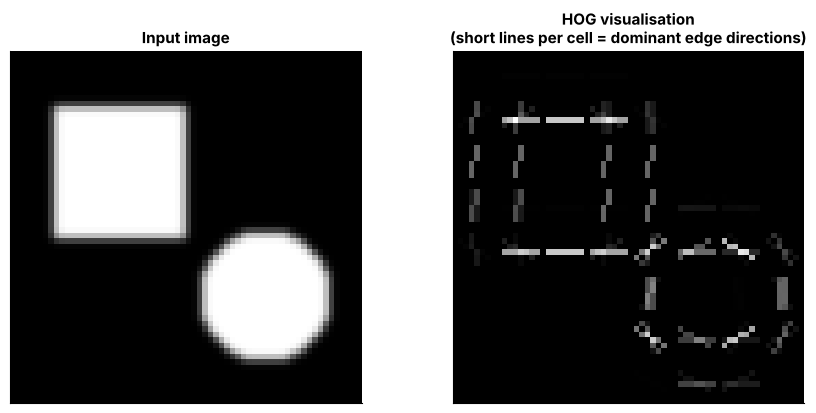

In [10]:
hog_vec, hog_picture = hog(shapes, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

n_cells = 64 // 8
n_blocks = n_cells - 2 + 1
expected = n_blocks * n_blocks * (2 * 2 * 9)
print(f"HOG vector length from scikit-image : {hog_vec.shape[0]}")
print(f"HOG vector length from our formula  : {n_blocks} x {n_blocks} blocks x 36 = {expected}")
assert hog_vec.shape[0] == expected

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
show_image(axes[0], shapes, "Input image")
show_image(axes[1], hog_picture, "HOG visualisation\n(short lines per cell = dominant edge directions)")
plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The assertion passed: we can predict the vector length from the settings. In the visualisation, each cell is drawn with little line segments *along the edges* (HOG's picture draws them perpendicular to the gradient). Flat areas stay dark. The picture is a *view* of the feature vector; the classifier receives the 1,764 numbers, not the picture.

## HOG on real clothing images
Fashion-MNIST images are tiny (28×28), so we use smaller cells: `pixels_per_cell=(4, 4)` → 7×7 cells → (7−2+1)² = 36 blocks × 36 = **1,296** numbers per image. (We chose this setting as a reasonable default for 28×28 images and did **not** tune it; a different setting would give different accuracy.)

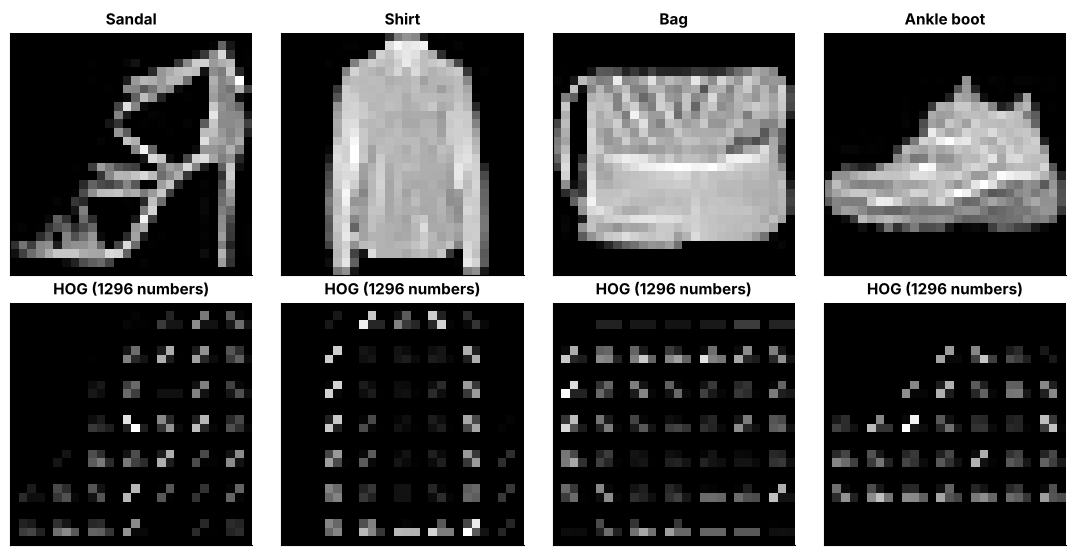

In [11]:
HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(4, 4), cells_per_block=(2, 2))

fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for col, cls in enumerate([5, 6, 8, 9]):                       # sandal, shirt, bag, ankle boot
    example = x_clf[np.where(y_clf == cls)[0][0]]
    vec, vis = hog(example, visualize=True, **HOG_SETTINGS)
    show_image(axes[0, col], example, CLASS_NAMES[cls])
    show_image(axes[1, col], vis, f"HOG ({vec.shape[0]} numbers)")
plt.tight_layout(); plt.show()

## The traditional pipeline: Image → HOG → classifier
Now compute HOG for all 5,000 classifier-training images and all 10,000 test images, and train the **same** logistic regression as before. Only the *features* change.

In [12]:
def hog_features(images):
    return np.array([hog(im, **HOG_SETTINGS) for im in images])

t0 = time.time(); hog_train = hog_features(x_clf);  hog_test = hog_features(x_test); hog_secs = time.time() - t0
print(f"HOG matrices: train {hog_train.shape}, test {hog_test.shape}  (extracted in {hog_secs:.1f} s)")

acc_hog, _, secs = fit_and_score(hog_train, hog_test)
print(f"HOG + Logistic Regression          -> test accuracy = {acc_hog:.3f}  (classifier trained in {secs:.1f} s)")
print(f"Raw pixels + Logistic Regression   -> test accuracy = {acc_raw:.3f}   (from Part 1)")

HOG matrices: train (5000, 1296), test (10000, 1296)  (extracted in 9.5 s)


HOG + Logistic Regression          -> test accuracy = 0.815  (classifier trained in 3.8 s)
Raw pixels + Logistic Regression   -> test accuracy = 0.793   (from Part 1)


**Interpretation [OBSERVED].** With the same classifier and the same training images, HOG features changed the accuracy compared with raw pixels (see the two numbers printed above). Edge-orientation summaries are a more useful description of shape than raw intensities, but the improvement is **not dramatic** on this dataset.

**What to take away.**

* HOG is a *fixed procedure*. Nothing in steps 1–4 was adjusted by looking at the labels. Only the final classifier was trained.
* The designer chose edges, 9 orientation bins and 4×4 cells. If those choices do not capture what separates *your* classes, the pipeline cannot fix them.

**Real-world connection.** HOG powered classic pedestrian detectors long before deep learning became popular, and it is still sensible on small datasets, on low-power devices, or when you can explain exactly what each feature measures.

**Common mistake.** Treating HOG's settings (cell size, bins) as "correct by default". They are *hyper-parameters*: choose them with a validation set, never with the test set.

---
# Part 3 · What is a CNN?

A **Convolutional Neural Network (CNN)** is a neural network designed for images. Its basic idea is surprisingly simple.

## Intuition: look through a small sliding window
Imagine looking at a large photo through a **small square window** — just 3×3 pixels. You slide the window across the picture, one step at a time, and at each position you ask the same simple question: *"Does the little patch under the window look like pattern X?"* and write down a score.

When you finish, your scores form a **new picture** that shows *where* pattern X appears. That new picture is called a **feature map**. A CNN does this with many different patterns at once, and then repeats the process on the feature maps.

We will build up the vocabulary one word at a time, always with real numbers.

| # | Term | Plain-English meaning |
|---|---|---|
| 1 | **Filter (kernel)** | A small matrix of numbers (e.g. 3×3). It is the "pattern X" the window looks for. |
| 2 | **Convolution** | Sliding the filter over the image; at each position, multiply patch × filter element by element and add everything up. |
| 3 | **Feature map** | The grid of scores produced by one filter: *where does this filter respond strongly?* |
| 4 | **Activation function (ReLU)** | A simple rule applied to each score: keep positive values, replace negative values by 0. |
| 5 | **Pooling** | Shrink a feature map by keeping only the strongest response in each small neighbourhood. |
| 6 | **CNN layers** | Stack these operations so later layers look at feature maps instead of raw pixels. |

> **Note on the word "convolution".** Strictly, mathematicians flip the filter before sliding it. Deep-learning libraries do **not** flip it (this is called *cross-correlation*). Because the filter values are *learned*, it makes no practical difference, and everybody still says "convolution".

## Step 1–3: a tiny image, a 3×3 filter, and one calculation by hand
Here is a 6×6 image. Large numbers are bright. The bright region on the right has a **vertical edge** where dark meets bright, and the edge ends before the bottom of the picture.
The filter below is **chosen by us for illustration** (it is a classic vertical-edge detector, called Prewitt): negative numbers on the left column, positive numbers on the right column, so it gives a big score where *left is dark and right is bright*.

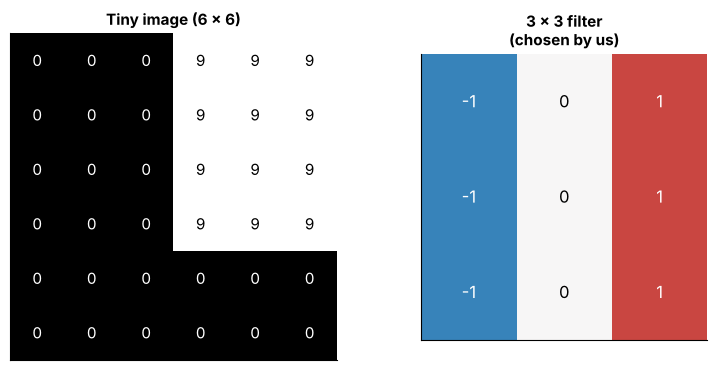

In [13]:
tiny_image = np.array([[0, 0, 0, 9, 9, 9],
                       [0, 0, 0, 9, 9, 9],
                       [0, 0, 0, 9, 9, 9],
                       [0, 0, 0, 9, 9, 9],
                       [0, 0, 0, 0, 0, 0],
                       [0, 0, 0, 0, 0, 0]], dtype=float)

vertical_edge = np.array([[-1, 0, 1],
                          [-1, 0, 1],
                          [-1, 0, 1]], dtype=float)           # hand-chosen, illustrative filter

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8), gridspec_kw={"width_ratios": [6, 3]})
axes[0].imshow(tiny_image, cmap="gray", vmin=0, vmax=9); annotate_cells(axes[0], tiny_image, color_switch=4.5, fontsize=11)
axes[0].set_title("Tiny image (6 x 6)")
axes[1].imshow(vertical_edge, cmap="RdBu_r", vmin=-1.5, vmax=1.5); annotate_cells(axes[1], vertical_edge, fontsize=12, abs_switch=0.5)
axes[1].set_title("3 x 3 filter\n(chosen by us)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### One output value, step by step
Place the filter on the image so its top-left corner is at some position, multiply every pair of overlapping numbers, and add them up. We do this at two positions:

* **Position (row 0, column 0):** the window looks at a flat dark area.
* **Position (row 0, column 1):** the window straddles the dark-to-bright edge.

In [14]:
def explain_position(image, kernel, r, c):
    k = kernel.shape[0]
    patch = image[r:r+k, c:c+k]
    products = patch * kernel                              # element-by-element multiplication
    print(f"--- window with top-left corner at (row {r}, column {c}) ---")
    print("image patch:\n", patch.astype(int))
    print("patch x filter (element by element):\n", products.astype(int))
    terms = " + ".join(str(int(v)) for v in products.ravel())
    print(f"sum = {terms} = {int(products.sum())}\n")
    return products.sum()

flat_score = explain_position(tiny_image, vertical_edge, 0, 0)
edge_score = explain_position(tiny_image, vertical_edge, 0, 1)

--- window with top-left corner at (row 0, column 0) ---
image patch:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
patch x filter (element by element):
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
sum = 0 + 0 + 0 + 0 + 0 + 0 + 0 + 0 + 0 = 0

--- window with top-left corner at (row 0, column 1) ---
image patch:
 [[0 0 9]
 [0 0 9]
 [0 0 9]]
patch x filter (element by element):
 [[0 0 9]
 [0 0 9]
 [0 0 9]]
sum = 0 + 0 + 9 + 0 + 0 + 9 + 0 + 0 + 9 = 27



**Interpretation [OBSERVED].**

* Over the flat dark area every pixel is 0, so every product is 0 and the **score is 0** — "no vertical edge here".
* Over the edge, the left column of the window sees 0s (multiplied by −1), the middle column sees 0s, and the right column sees 9s (multiplied by +1). The nine products add up to **27** — a large positive score — "a dark→bright vertical edge is here".

The score is a *measurement of how well the patch matches the filter's pattern*.

### Slide the filter over every position → a feature map
We now repeat the calculation at every position (a short loop), producing the whole feature map. With no padding, a 3×3 filter fits in (6−3+1) = **4 positions** across and 4 down, so the output is 4×4.

(We also check our loop against SciPy's built-in version to be sure it is right.)

Feature map shape: (4, 4) (= 6 - 3 + 1 in each direction)
[[ 0 27 27  0]
 [ 0 27 27  0]
 [ 0 18 18  0]
 [ 0  9  9  0]]


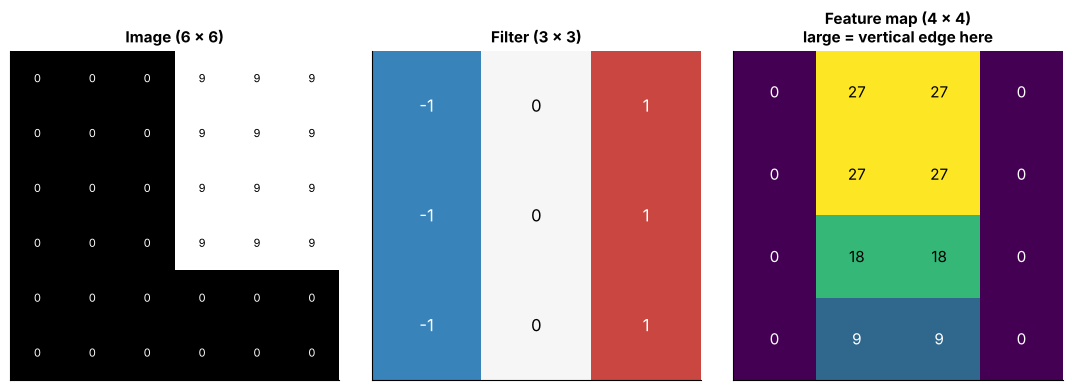

In [15]:
from scipy.signal import correlate2d

def conv2d_valid(image, kernel):
    """Slide `kernel` over `image` (no padding, step = 1). Output size = (H - k + 1) x (W - k + 1)."""
    H, W = image.shape
    k = kernel.shape[0]
    out = np.zeros((H - k + 1, W - k + 1))
    for r in range(out.shape[0]):
        for c in range(out.shape[1]):
            out[r, c] = np.sum(image[r:r+k, c:c+k] * kernel)
    return out

feature_map = conv2d_valid(tiny_image, vertical_edge)
assert np.allclose(feature_map, correlate2d(tiny_image, vertical_edge, mode="valid"))
print("Feature map shape:", feature_map.shape, "(= 6 - 3 + 1 in each direction)")
print(feature_map.astype(int))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(tiny_image, cmap="gray", vmin=0, vmax=9); annotate_cells(axes[0], tiny_image, color_switch=4.5)
axes[0].set_title("Image (6 x 6)")
axes[1].imshow(vertical_edge, cmap="RdBu_r", vmin=-1.5, vmax=1.5); annotate_cells(axes[1], vertical_edge, abs_switch=0.5, fontsize=12)
axes[1].set_title("Filter (3 x 3)")
axes[2].imshow(feature_map, cmap="viridis"); annotate_cells(axes[2], feature_map, color_switch=feature_map.max()/2, fontsize=11)
axes[2].set_title("Feature map (4 x 4)\nlarge = vertical edge here")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The feature map is large (27) in the two columns that straddle the edge and 0 elsewhere. It also gets **weaker toward the bottom** (27 → 18 → 9) because the edge gets shorter there: fewer rows of the window see it. So a feature map tells you **where** a pattern occurs and **how strongly**.

## Step 4–5: activation (ReLU) and pooling
Real images have edges in both directions: a bright bar on a dark background has a **dark→bright** edge on its left side (positive score) and a **bright→dark** edge on its right side (negative score).

* **ReLU** (Rectified Linear Unit) keeps positive scores and sets negative scores to 0: `ReLU(x) = max(0, x)`. It lets the network say "this pattern is present" without a negative "anti-pattern" confusing later layers, and it makes the whole network able to learn **non-linear** relationships.
* **Max pooling (2×2)** looks at each non-overlapping 2×2 block of the feature map and keeps only the **largest** value. The map becomes half as wide and half as tall, which means less computation downstream and a little tolerance to small shifts (only a *little* — pooling does not make a CNN perfectly shift-proof).

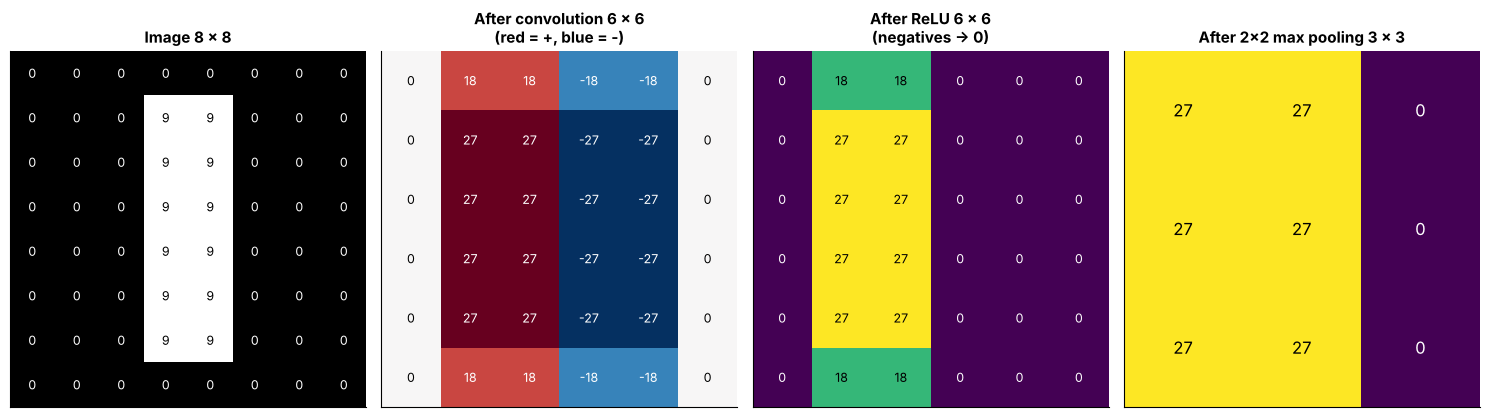

Shapes: (8, 8) -> (6, 6) -> (6, 6) -> (3, 3)


In [16]:
bar = np.zeros((8, 8)); bar[1:7, 3:5] = 9                      # a bright vertical bar on a dark background
conv_out = conv2d_valid(bar, vertical_edge)                    # 6 x 6; left edge of bar -> +, right edge -> -
relu_out = np.maximum(conv_out, 0)                             # ReLU: negatives become 0

def max_pool_2x2(fmap):
    H, W = fmap.shape
    return fmap[:H//2*2, :W//2*2].reshape(H//2, 2, W//2, 2).max(axis=(1, 3))

pooled = max_pool_2x2(relu_out)

stages = [("Image 8 x 8", bar, "gray", (0, 9)),
          ("After convolution 6 x 6\n(red = +, blue = -)", conv_out, "RdBu_r", (-27, 27)),
          ("After ReLU 6 x 6\n(negatives -> 0)", relu_out, "viridis", (0, 27)),
          ("After 2x2 max pooling 3 x 3", pooled, "viridis", (0, 27))]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (title, data, cmap, (lo, hi)) in zip(axes, stages):
    ax.imshow(data, cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    diverging = cmap == "RdBu_r"
    annotate_cells(ax, data, color_switch=None if diverging else (lo + hi) / 2, abs_switch=13 if diverging else None,
                   fontsize=9 if data.shape[0] > 3 else 12)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print("Shapes:", bar.shape, "->", conv_out.shape, "->", relu_out.shape, "->", pooled.shape)

**Interpretation [OBSERVED].** After convolution we see a **positive** column (left side of the bar) and a **negative** column (right side). ReLU removes the negatives, so only "dark→bright vertical edge" survives. Max pooling then shrinks the 6×6 map to 3×3 while keeping the strongest responses of each neighbourhood.

> This particular filter detects only one kind of edge. A CNN uses **many** filters at the same time, so it can detect many different patterns.

## The same operation on a real image (with hand-chosen filters)
Now we apply four filters **that we picked by hand** to a sneaker image — to see what "feature maps" look like on a real picture. These are *illustrative classic filters*, not filters learned by a CNN.

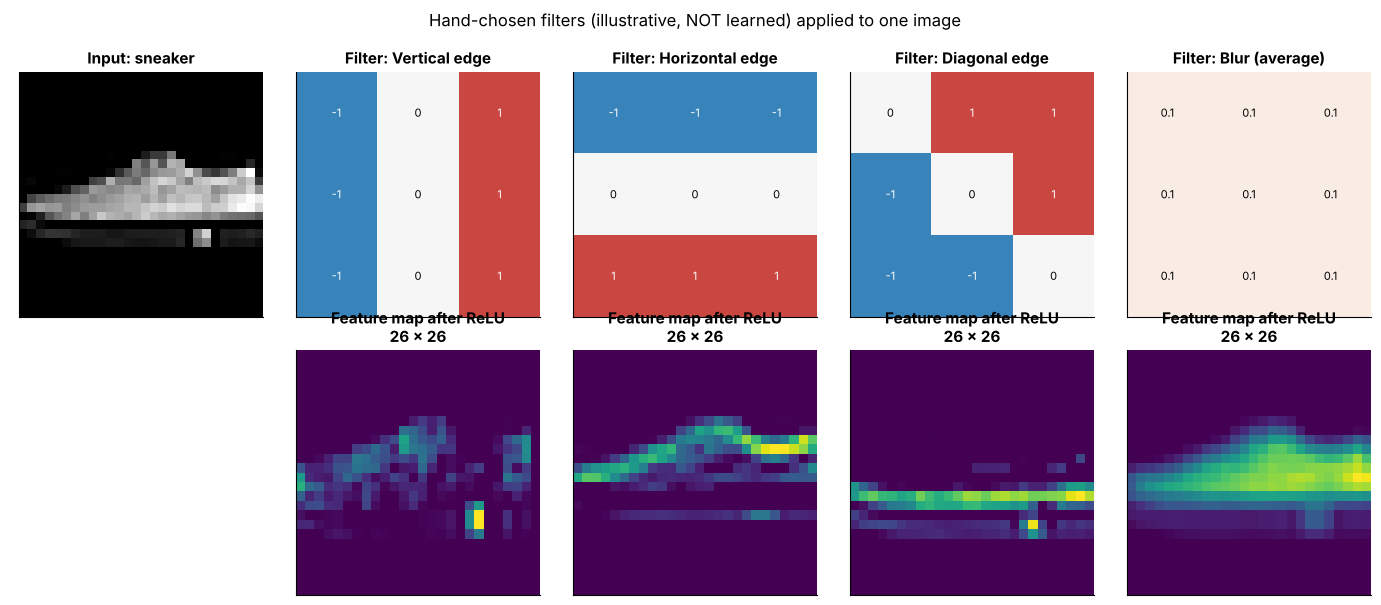

In [17]:
hand_filters = {
    "Vertical edge":   np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float),
    "Horizontal edge": np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=float),
    "Diagonal edge":   np.array([[0, 1, 1], [-1, 0, 1], [-1, -1, 0]], dtype=float),
    "Blur (average)":  np.ones((3, 3)) / 9.0,
}
sneaker = x_clf[np.where(y_clf == 7)[0][0]]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
show_image(axes[0, 0], sneaker, "Input: sneaker")
axes[1, 0].axis("off")
for col, (name, kern) in enumerate(hand_filters.items(), start=1):
    out = np.maximum(conv2d_valid(sneaker, kern), 0)                       # convolution followed by ReLU
    axes[0, col].imshow(kern, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
    annotate_cells(axes[0, col], kern, fmt="{:.1f}" if name.startswith("Blur") else "{:.0f}", abs_switch=0.5)
    axes[0, col].set_title(f"Filter: {name}"); axes[0, col].set_xticks([]); axes[0, col].set_yticks([])
    show_image(axes[1, col], out, f"Feature map after ReLU\n{out.shape[0]} x {out.shape[1]}", cmap="viridis")
plt.suptitle("Hand-chosen filters (illustrative, NOT learned) applied to one image", y=1.0)
plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The vertical-edge map lights up along the sneaker's up-and-down outlines; the horizontal-edge map lights up along its soles and top; the diagonal filter responds to slanted parts; the blur filter gives a smoothed version of the image. Different filters ⇒ different feature maps ⇒ different *views* of the same picture. Notice the output is 26×26 (28 − 3 + 1).

## From these ideas to a real CNN layer

In Keras, `Conv2D(16, kernel_size=3)` means "use **16 filters**, each 3×3". For a grayscale input every filter has 3×3 = 9 weights plus 1 bias = **10 parameters**, so that layer has 16 × 10 = **160 parameters**. For a later layer that receives 16 feature maps, each filter is 3×3×**16** (it looks at *all* incoming maps at once) plus a bias.

**Crucial difference from what we just did:**

| | Filters in this part | Filters in a real CNN |
|---|---|---|
| Who chose the numbers? | **We did** (Prewitt, blur, ...) | **Training** adjusts them (they start random) |
| Are they all edge detectors? | We designed them to be | **Not necessarily** — each filter ends up as whatever helps the task |
| How many? | 4 | Tens to thousands, in many layers |

The rest of the notebook answers the next question: **how can a network find good filter numbers on its own?**

---
# Part 4 · How does a CNN learn edges, textures and shapes?

*This is the most important conceptual part of the notebook.*

## Intuition: a CNN that tells cats from dogs   **[INTUITION]**
Imagine we train a CNN on thousands of labelled photos of cats and dogs. A **helpful mental picture** of what its layers may end up doing:

| Layer depth | What it may respond to | Cat/dog flavour |
|---|---|---|
| **Early layers** | Simple local patterns: edges, orientations, colour changes | "a dark-to-bright boundary running diagonally" |
| **Middle layers** | Combinations of those: textures, corners, curves, repeated patterns | "fur-like texture", "a curved outline" |
| **Deeper layers** | Larger, more complex arrangements that help to separate the classes | "something ear-shaped and pointed", "a snout-like region" |

### Read this carefully — it is a generalisation, not a law
* This progression (simple → complex) is a **useful intuition** and is often seen in practice, but it is **not guaranteed** and not a fixed recipe. What a CNN learns depends on its **architecture**, the **data**, the **training process** and the **task** (its loss function).
* Individual filters are **not** labelled by the network. A filter is just a set of numbers. People sometimes *interpret* a pattern as "ear detector", but that is a human story added afterwards. We will not make such claims without evidence.
* Nobody wrote instructions like *"detect an ear"* or *"detect a wheel"*. The only guidance is: **"make the prediction error smaller."**

## How learning actually happens (the training loop)
A CNN starts with **random** filter numbers. Then it repeats these six steps many times:

1. **Receive training images** (a small batch, with their true labels).
2. **Produce predictions** (the "forward pass": image → conv layers → feature maps → output).
3. **Measure the error** with a **loss function** — one number that says how wrong the predictions were (bigger = worse).
4. **Backpropagation** works out, for every single parameter, *"if I nudged you slightly up or down, would the loss go up or down, and by how much?"* (that answer is called the **gradient**).
5. The **optimizer** (e.g. Adam) nudges every parameter a small step in the direction that *reduces* the loss.
6. **Repeat** over many batches and passes through the data (**epochs**). Parameters that produce features useful for the task get reinforced.

Analogy: tuning thousands of radio knobs at once. After every attempt, a scoring machine tells each knob which way to turn so the sound gets slightly less noisy.

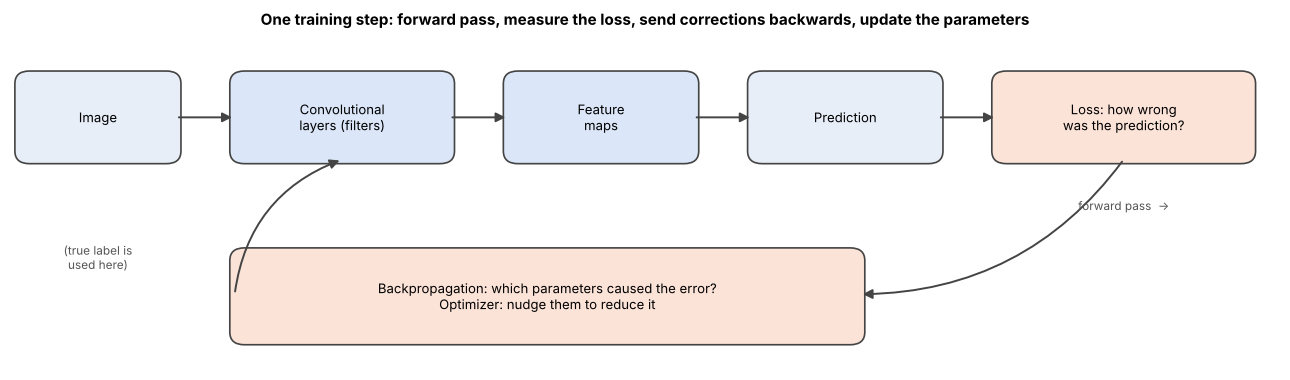

In [18]:
def draw_training_loop():
    fig, ax = plt.subplots(figsize=(13, 3.9)); ax.set_xlim(0, 13); ax.set_ylim(0, 4); ax.axis("off")
    def box(x, y, w, h, text, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15", fc=color, ec="#444", lw=1.2))
        ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9.5)
    def arrow(p, q, **kw):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=14, lw=1.4, color="#444", **kw))
    top = 2.5
    box(0.1, top, 1.6, 1.0, "Image", "#e8eef8")
    box(2.3, top, 2.2, 1.0, "Convolutional\nlayers (filters)", "#dbe7f8")
    box(5.1, top, 1.9, 1.0, "Feature\nmaps", "#dbe7f8")
    box(7.6, top, 1.9, 1.0, "Prediction", "#e8eef8")
    box(10.1, top, 2.6, 1.0, "Loss: how wrong\nwas the prediction?", "#fbe3d8")
    for a, b in [(1.7, 2.3), (4.5, 5.1), (7.0, 7.6), (9.5, 10.1)]:
        arrow((a, top + 0.5), (b, top + 0.5))
    box(2.3, 0.35, 6.4, 1.05, "Backpropagation: which parameters caused the error?\nOptimizer: nudge them to reduce it", "#fbe3d8")
    arrow((11.4, top), (8.7, 0.9), connectionstyle="arc3,rad=-0.25")
    arrow((2.3, 0.9), (3.4, top), connectionstyle="arc3,rad=-0.3")
    ax.text(0.9, 1.2, "(true label is\nused here)", fontsize=8.5, color="#555", ha="center")
    ax.text(11.4, 1.9, "forward pass  ->", fontsize=8.5, color="#555", ha="center")
    ax.set_title("One training step: forward pass, measure the loss, send corrections backwards, update the parameters", fontsize=11)
    plt.tight_layout(); plt.show()
draw_training_loop()

**Reading the diagram [INTUITION].** Top row = the *forward pass*: image → convolutional layers → feature maps → prediction. The loss compares the prediction with the true label. The bottom box = the *learning signal*: errors flow backwards, and the filter numbers inside the convolutional layers get updated. After thousands of repetitions the filters are no longer random.

### The smallest possible example of "learning"
Before a CNN, let us see the update rule on **one parameter**. Suppose the "model" is `prediction = w * x`, the input is `x = 2`, and the true answer is `y = 6`. The loss is `(prediction - y)^2`. The gradient (slope of the loss with respect to `w`) is `2 * (prediction - y) * x`. We repeatedly move `w` a little against the gradient (`learning rate = 0.05`).

In [19]:
w, x, y, lr = 0.0, 2.0, 6.0, 0.05
print(f"{'step':>4} {'w':>7} {'prediction':>11} {'loss':>8} {'gradient':>9}")
for step in range(8):
    pred = w * x
    loss = (pred - y) ** 2
    grad = 2 * (pred - y) * x
    print(f"{step:>4} {w:>7.3f} {pred:>11.3f} {loss:>8.3f} {grad:>9.3f}")
    w = w - lr * grad                       # the update: move AGAINST the gradient
print("\nThe best possible w is 6 / 2 = 3. After 8 steps w =", round(w, 3))

step       w  prediction     loss  gradient
   0   0.000       0.000   36.000   -24.000
   1   1.200       2.400   12.960   -14.400
   2   1.920       3.840    4.666    -8.640
   3   2.352       4.704    1.680    -5.184
   4   2.611       5.222    0.605    -3.110
   5   2.767       5.533    0.218    -1.866
   6   2.860       5.720    0.078    -1.120
   7   2.916       5.832    0.028    -0.672

The best possible w is 6 / 2 = 3. After 8 steps w = 2.95


**Interpretation [OBSERVED].** The loss shrinks at every step and `w` moves towards 3. A CNN does exactly this, but for thousands or millions of parameters at once, and **backpropagation** is the efficient way to compute all the gradients.

## Watch a CNN discover filters (a toy experiment)
Can a network find an edge-like filter **without being told what an edge is**? We create a tiny, *synthetic* problem (generated by us — it is a toy, not a real dataset):

* Class 0: images with **vertical stripes**; Class 1: images with **horizontal stripes**; with random stripe width, position and a little noise.
* The model: **one** convolutional layer with **2 filters (3×3)** → ReLU → global average pooling → a 2-way classifier.
* The only supervision: the label "vertical" or "horizontal". We never mention edges.

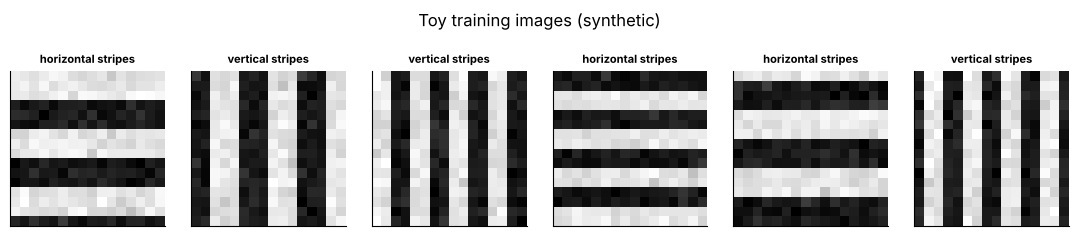

Training images: (600, 16, 16, 1) | validation images: (200, 16, 16, 1)


In [20]:
def make_stripes(n, rng, size=16):
    """Synthetic toy data: class 0 = vertical stripes, class 1 = horizontal stripes (+ noise)."""
    X = np.zeros((n, size, size, 1), dtype="float32"); y = np.zeros(n, dtype=int)
    for i in range(n):
        y[i] = rng.integers(2); width = rng.integers(2, 4); phase = rng.integers(0, 2 * width)
        pattern = ((np.arange(size) + phase) // width) % 2
        stripes = np.tile(pattern, (size, 1)) if y[i] == 0 else np.tile(pattern[:, None], (1, size))
        X[i, :, :, 0] = stripes * 0.8 + 0.1 + rng.normal(0, 0.05, (size, size))
    return X, y

rng = np.random.default_rng(0)
Xs_train, ys_train = make_stripes(600, rng)
Xs_val,   ys_val   = make_stripes(200, rng)

fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for k, ax in enumerate(axes):
    show_image(ax, Xs_train[k, :, :, 0], ["vertical stripes", "horizontal stripes"][ys_train[k]], vmin=0, vmax=1)
    ax.title.set_fontsize(8)
plt.suptitle("Toy training images (synthetic)", y=1.05); plt.tight_layout(); plt.show()
print("Training images:", Xs_train.shape, "| validation images:", Xs_val.shape)

Now we train the tiny network three times with different random starting filters (three **seeds**), and keep a copy of the filters **before** and **after** training. We also compare each learned filter with an *ideal* vertical-edge template and horizontal-edge template using **cosine similarity** (1 = same pattern, −1 = same pattern with opposite sign, 0 = unrelated).

In [21]:
def cosine(a, b):
    a, b = a.ravel(), b.ravel()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

prewitt_v = hand_filters["Vertical edge"]       # templates for comparison only
prewitt_h = hand_filters["Horizontal edge"]

toy_results = []
for seed in [0, 1, 2]:
    keras.utils.set_random_seed(seed)
    toy = keras.Sequential([
        keras.Input((16, 16, 1)),
        layers.Conv2D(2, 3, activation="relu", name="toy_conv"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(2, activation="softmax"),
    ])
    before = toy.get_layer("toy_conv").get_weights()[0][:, :, 0, :].copy()           # shape (3, 3, 2)
    toy.compile(optimizer=keras.optimizers.Adam(0.02), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = toy.fit(Xs_train, ys_train, epochs=30, batch_size=32, verbose=0, validation_data=(Xs_val, ys_val))
    after = toy.get_layer("toy_conv").get_weights()[0][:, :, 0, :]
    toy_results.append(dict(seed=seed, before=before, after=after.copy(), hist=hist.history))
    print(f"seed {seed}: loss {hist.history['loss'][0]:.3f} -> {hist.history['loss'][-1]:.4f} | "
          f"validation accuracy {hist.history['val_accuracy'][-1]:.2f}")
    for f in range(2):
        print(f"    filter {f}: similarity to vertical-edge template = {cosine(after[:, :, f], prewitt_v):+.2f}, "
              f"to horizontal-edge template = {cosine(after[:, :, f], prewitt_h):+.2f}")

seed 0: loss 0.614 -> 0.0019 | validation accuracy 1.00
    filter 0: similarity to vertical-edge template = +0.09, to horizontal-edge template = +0.24
    filter 1: similarity to vertical-edge template = -0.00, to horizontal-edge template = +0.99


seed 1: loss 0.675 -> 0.0081 | validation accuracy 1.00
    filter 0: similarity to vertical-edge template = -0.01, to horizontal-edge template = +0.00
    filter 1: similarity to vertical-edge template = -0.16, to horizontal-edge template = -0.12


seed 2: loss 0.675 -> 0.0043 | validation accuracy 1.00
    filter 0: similarity to vertical-edge template = -0.98, to horizontal-edge template = +0.00
    filter 1: similarity to vertical-edge template = +0.12, to horizontal-edge template = -0.12


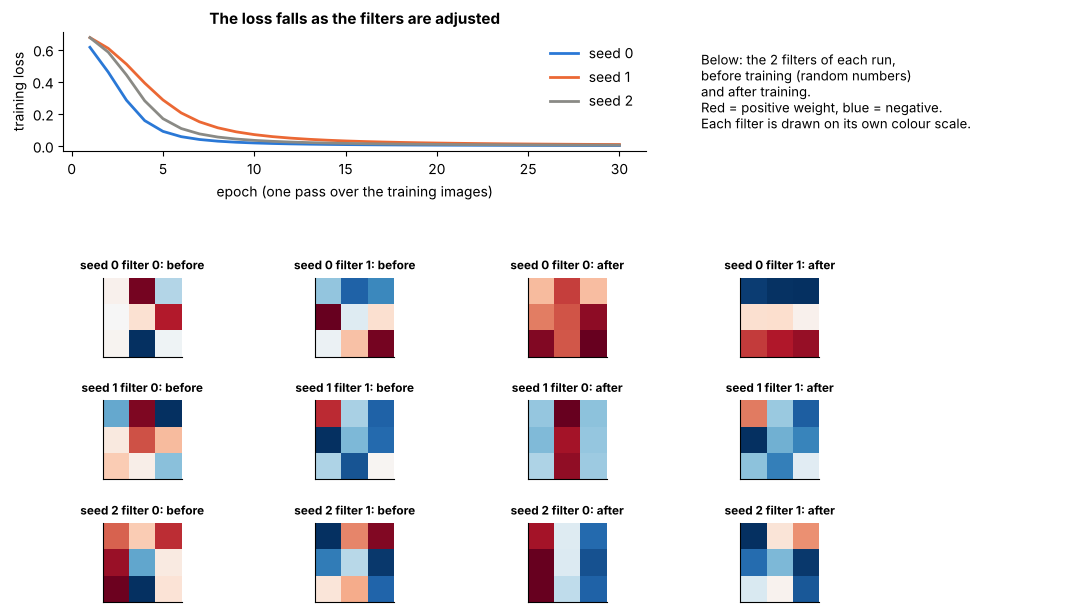

In [22]:
fig = plt.figure(figsize=(13, 7.4))
gs = fig.add_gridspec(5, 5, height_ratios=[1.5, 0.5, 1, 1, 1], hspace=0.55, wspace=0.35)   # row 1 is an empty spacer

ax = fig.add_subplot(gs[0, :3])
for r, color in zip(toy_results, [BLUE, ORANGE, GREY]):
    ax.plot(range(1, 31), r["hist"]["loss"], color=color, lw=2, label=f"seed {r['seed']}")
ax.set_xlabel("epoch (one pass over the training images)"); ax.set_ylabel("training loss"); ax.legend(frameon=False)
ax.set_title("The loss falls as the filters are adjusted")
ax2 = fig.add_subplot(gs[0, 3:])
ax2.axis("off")
ax2.text(0, 0.5, "Below: the 2 filters of each run,\nbefore training (random numbers)\nand after training.\n"
         "Red = positive weight, blue = negative.\nEach filter is drawn on its own colour scale.", fontsize=9.5, va="center")

for row, r in enumerate(toy_results, start=2):
    for f in range(2):
        for col_offset, key, label in [(0, "before", "before"), (2, "after", "after")]:
            axf = fig.add_subplot(gs[row, col_offset + f])
            k = r[key][:, :, f]; lim = np.abs(k).max()
            axf.imshow(k, cmap="RdBu_r", vmin=-lim, vmax=lim)
            axf.set_xticks([]); axf.set_yticks([])
            axf.set_title(f"seed {r['seed']} filter {f}: {label}", fontsize=8.5)
plt.show()

**Interpretation.**

* **[OBSERVED]** The loss drops steeply and the validation accuracy ends near 1.00: the network solved the toy task.
* **[OBSERVED]** Before training, the filters are patternless random numbers. After training, in some runs a filter becomes **almost a copy of an edge template**: look at the printed similarities above — a value close to +1 or −1 means "nearly the same pattern" (−1 = same pattern with opposite signs, which the network can compensate for later). In our run this happened for two of the three seeds; for the third seed neither filter matches the two edge templates (one has a red middle column with blue sides, a thin-line-like pattern), yet the task is solved just as well.
* **[OBSERVED]** The three seeds ended up with **different** filters — different signs, different orientations. There is no single "correct" filter set; any combination that makes the task easy gets rewarded. (Your numbers may differ from ours, but you should see the same kind of variety.)
* **[INTERPRETATION]** The edge-like look of the learned filters is not magic: stripe orientation is exactly the information needed for this task, and gradient descent found filters that measure it. We never told the network to use edges.
* **Limit of this demo.** It is a deliberately easy toy problem with synthetic data. It shows that *learning can produce structured, edge-like filters in some runs*; it does **not** prove that every CNN filter on real photos will be an edge detector.

**Real-world connection.** This is why CNNs are called **feature learners**: the *feature extraction rules* (the filters) are parameters estimated from data, not hand-written code. That is also why the **training data** and **task** become part of your feature-engineering pipeline.

---
# Part 5 · Visualise filters and feature maps (a small CNN on real images)

Now the real thing: a small CNN trained on 30,000 Fashion-MNIST images, on your CPU, in about a minute.

## The architecture (read it top to bottom)
```
Input (28 x 28 x 1)
  -> Conv2D  16 filters 3x3  + ReLU     "conv1"   early layer
  -> MaxPool 2x2                         "pool1"
  -> Conv2D  32 filters 3x3  + ReLU     "conv2"   middle layer
  -> MaxPool 2x2                         "pool2"
  -> Conv2D  64 filters 3x3  + ReLU     "conv3"   deeper layer
  -> Global Average Pooling              "gap"     64 numbers per image   <- our feature vector (Part 6)
  -> Dense 10 + softmax                  "classifier"  the final prediction head
```
Everything up to `gap` turns an image into a vector of **64 learned numbers**. The last layer (`classifier`) turns those 64 numbers into 10 class probabilities. Because the last layer is separate, we can later **cut it off** and use the 64 numbers as features.

**Tensor shapes.** Keras expects image batches shaped `(batch, height, width, channels)`. Our grayscale images have 1 channel, so we add that axis with `x[..., None]`.

In [23]:
def build_cnn(seed=SEED):
    keras.utils.set_random_seed(seed)                      # same seed -> same random starting filters
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, activation="relu", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(32, 3, activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Conv2D(64, 3, activation="relu", name="conv3"),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(10, activation="softmax", name="classifier"),
    ], name="small_cnn")

cnn = build_cnn()
cnn.summary()

# Check our hand-calculation from Part 3:  filters x (kernel_h * kernel_w * in_channels + 1 bias)
expected = (16*(3*3*1+1)) + (32*(3*3*16+1)) + (64*(3*3*32+1)) + (64*10+10)
print(f"\nParameters we calculated by hand: {expected:,} | Keras says: {cnn.count_params():,}")
assert expected == cnn.count_params()

Model: "small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 3, 3, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,946 (93.54 KB)

 Trainable params: 23,946 (93.54 KB)

 Non-trainable params: 0 (0.00 B)


Parameters we calculated by hand: 23,946 | Keras says: 23,946


**Interpretation [OBSERVED].** Look at the *Output Shape* column. The picture shrinks (28→26→13→11→5→3) while the number of feature maps grows (1→16→32→64). `gap` squeezes each of the 64 maps into a single number, giving a 64-number summary. About 24,000 parameters in total is **tiny** for a neural network (modern image models have millions to billions), which is why it trains on a laptop.

## Train it
We save a copy of the **untrained** first-layer filters first, so we can compare them with the trained ones.

* `loss="sparse_categorical_crossentropy"` – the loss for multi-class problems when labels are integers 0–9.
* `Adam` – a popular optimizer; `3e-3` is its learning rate (step size).
* `epochs=10` – ten passes over the 30,000 training images; `batch_size=128` – update the parameters after every 128 images.
* `validation_split=0.1` – hold out 10% of the 30,000 images to check how well the CNN does on pictures it is not training on.

In [24]:
filters_before = cnn.get_layer("conv1").get_weights()[0].copy()      # shape (3, 3, 1, 16): 16 random 3x3 filters

cnn.compile(optimizer=keras.optimizers.Adam(3e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
history = cnn.fit(x_cnn[..., None], y_cnn, epochs=10, batch_size=128, validation_split=0.1, verbose=2)
print(f"\nTraining took {time.time() - t0:.0f} seconds on this machine.")

Epoch 1/10


211/211 - 5s - 25ms/step - accuracy: 0.6740 - loss: 0.8976 - val_accuracy: 0.7383 - val_loss: 0.7005


Epoch 2/10


211/211 - 4s - 19ms/step - accuracy: 0.7811 - loss: 0.5758 - val_accuracy: 0.7757 - val_loss: 0.6009


Epoch 3/10


...

Epoch 9/10


211/211 - 6s - 26ms/step - accuracy: 0.8772 - loss: 0.3386 - val_accuracy: 0.8723 - val_loss: 0.3650


Epoch 10/10


211/211 - 4s - 19ms/step - accuracy: 0.8822 - loss: 0.3253 - val_accuracy: 0.8757 - val_loss: 0.3531



Training took 45 seconds on this machine.


CNN (with its own final layer) on the 10,000 test images: accuracy = 0.868


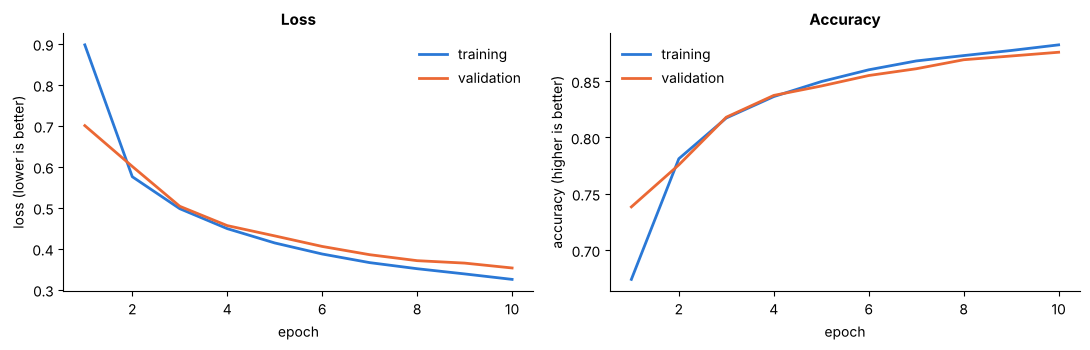

Per-class test accuracy, hardest first:
   Shirt        0.62
   T-shirt/top  0.73
   Dress        0.81
   Pullover     0.82


In [25]:
test_loss, test_acc = cnn.evaluate(x_test[..., None], y_test, verbose=0)
print(f"CNN (with its own final layer) on the 10,000 test images: accuracy = {test_acc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
epochs = range(1, len(history.history["loss"]) + 1)
axes[0].plot(epochs, history.history["loss"], color=BLUE, lw=2, label="training")
axes[0].plot(epochs, history.history["val_loss"], color=ORANGE, lw=2, label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (lower is better)"); axes[0].set_title("Loss"); axes[0].legend(frameon=False)
axes[1].plot(epochs, history.history["accuracy"], color=BLUE, lw=2, label="training")
axes[1].plot(epochs, history.history["val_accuracy"], color=ORANGE, lw=2, label="validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (higher is better)"); axes[1].set_title("Accuracy"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

pred_test = cnn.predict(x_test[..., None], verbose=0).argmax(axis=1)
per_class = [(CLASS_NAMES[k], float((pred_test[y_test == k] == k).mean())) for k in range(10)]
print("Per-class test accuracy, hardest first:")
for name, a in sorted(per_class, key=lambda t: t[1])[:4]:
    print(f"   {name:<12} {a:.2f}")

**Interpretation [OBSERVED].** The loss falls and accuracy rises over the epochs; validation curves follow the training curves closely, so the network is learning something that carries over to unseen images rather than just memorising. The hardest classes are the ones that genuinely look alike (upper-body garments such as shirts, T-shirts, pullovers and dresses) — see the printed list.

> **Common misconception:** "A CNN always reaches 99%." Not true. This is a deliberately small network, trained briefly. Bigger models, more data and longer training would do better — at higher cost.

## Look 1: the first-layer filters, before and after training
`conv1` has 16 filters of size 3×3. We draw each as a tiny image: **red = positive weight, blue = negative weight, white ≈ 0** (each figure uses one colour scale for all its filters).

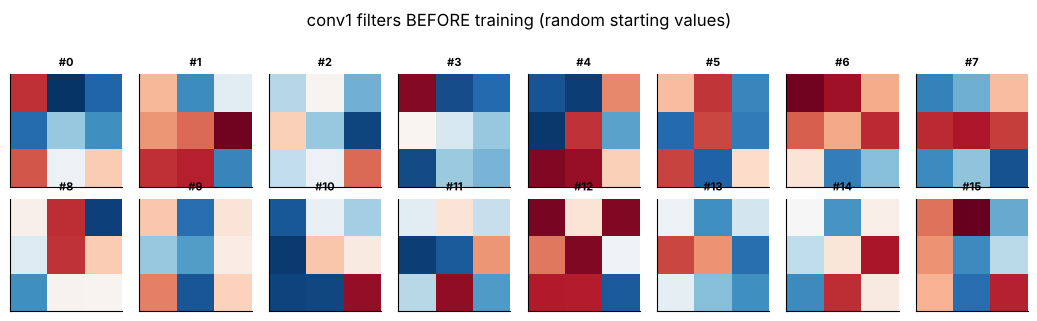

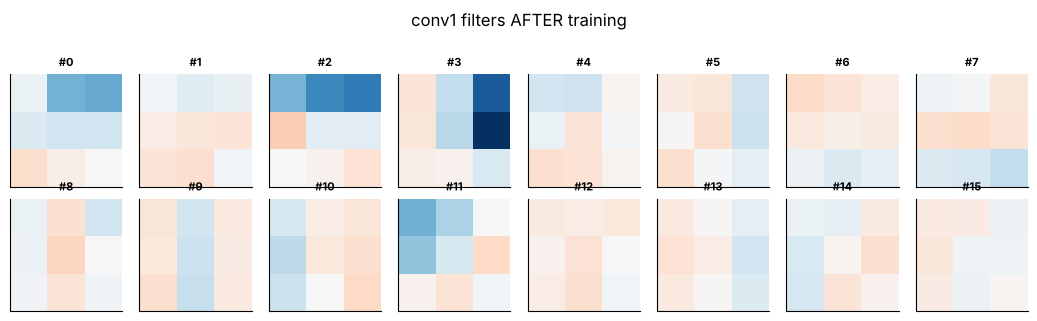

Average |weight| before: 0.103   after: 0.289
Largest change of any single weight: 1.944


In [26]:
def plot_filters(weights, title):
    """weights has shape (3, 3, 1, n_filters). Draw every 3x3 filter as a small diverging-colour image."""
    n = weights.shape[-1]; lim = np.abs(weights).max()
    fig, axes = plt.subplots(2, n // 2, figsize=(1.3 * n // 2 + 0.5, 3.1))
    for k, ax in enumerate(axes.ravel()):
        ax.imshow(weights[:, :, 0, k], cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"#{k}", fontsize=8)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

filters_after = cnn.get_layer("conv1").get_weights()[0]
plot_filters(filters_before, "conv1 filters BEFORE training (random starting values)")
plot_filters(filters_after,  "conv1 filters AFTER training")
print(f"Average |weight| before: {np.abs(filters_before).mean():.3f}   after: {np.abs(filters_after).mean():.3f}")
print(f"Largest change of any single weight: {np.abs(filters_after - filters_before).max():.3f}")

**What we can observe [OBSERVED]:** training changed the numbers (the average weight size grew and some weights moved a lot). Most untrained filters look like random noise. After training, a handful of filters have visibly larger weights with a clear positive/negative split (they *look* edge-like), while many others stay small and faint on this shared colour scale.

**What is only an interpretation [INTERPRETATION]:** it is tempting to say "filter #3 detects diagonal edges". A 3×3 filter picture shows *numbers*, not *meaning*. Some filters in this layer look edge-like, others do not look like anything a person would name. We do not label them. To claim what a filter "detects", you would need evidence — for example by checking which image patches make it respond most, or by switching it off and seeing what breaks.

## Look 2: feature maps — what do the layers output for one image?
We build a helper model that returns the output of several layers for the same input, then show a few feature maps from an **early** layer (`conv1`), a **middle** layer (`conv2`) and a **deeper** layer (`conv3`).

In [27]:
layer_names = ["conv1", "pool1", "conv2", "pool2", "conv3"]
feature_model = keras.Model(cnn.inputs, [cnn.get_layer(n).output for n in layer_names])

probe_index = np.where(y_test == 9)[0][0]                     # the first "Ankle boot" in the test set
probe = x_test[probe_index]
probe_outputs = feature_model.predict(probe[None, ..., None], verbose=0)     # add batch axis AND channel axis
pred_probs = cnn.predict(probe[None, ..., None], verbose=0)[0]

print(f"True class: {CLASS_NAMES[y_test[probe_index]]} | CNN prediction: {CLASS_NAMES[pred_probs.argmax()]} (probability {pred_probs.max():.2f})\n")
print(f"{'layer':<8} {'output shape (batch, H, W, maps)':<36} {'values that are exactly 0 (ReLU)':>30}")
print(f"{'input':<8} {str((1, 28, 28, 1)):<36}")
for name, out in zip(layer_names, probe_outputs):
    zero_share = (out == 0).mean() if name.startswith("conv") else float("nan")
    note = f"{zero_share:>29.0%}" if name.startswith("conv") else f"{'':>30}"
    print(f"{name:<8} {str(out.shape):<36} {note}")

True class: Ankle boot | CNN prediction: Ankle boot (probability 0.96)

layer    output shape (batch, H, W, maps)     values that are exactly 0 (ReLU)
input    (1, 28, 28, 1)                      
conv1    (1, 26, 26, 16)                                                49%
pool1    (1, 13, 13, 16)                                                    
conv2    (1, 11, 11, 32)                                                66%
pool2    (1, 5, 5, 32)                                                      
conv3    (1, 3, 3, 64)                                                  55%


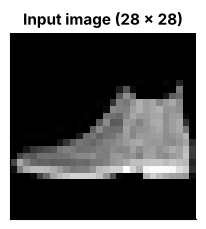

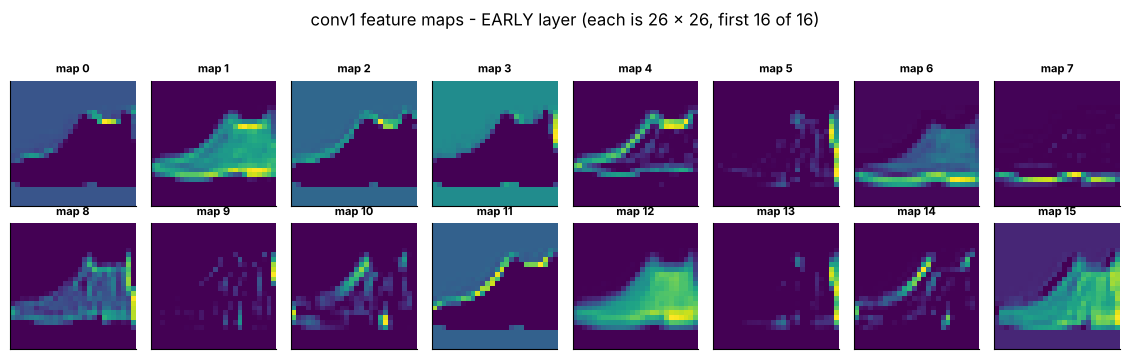

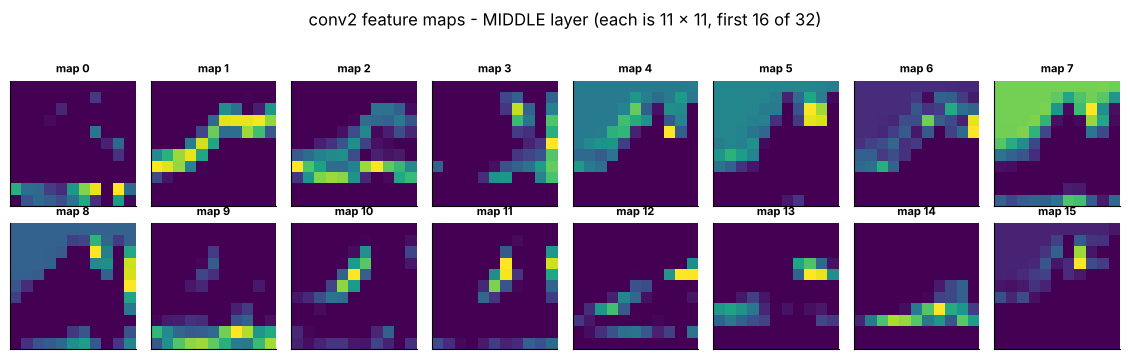

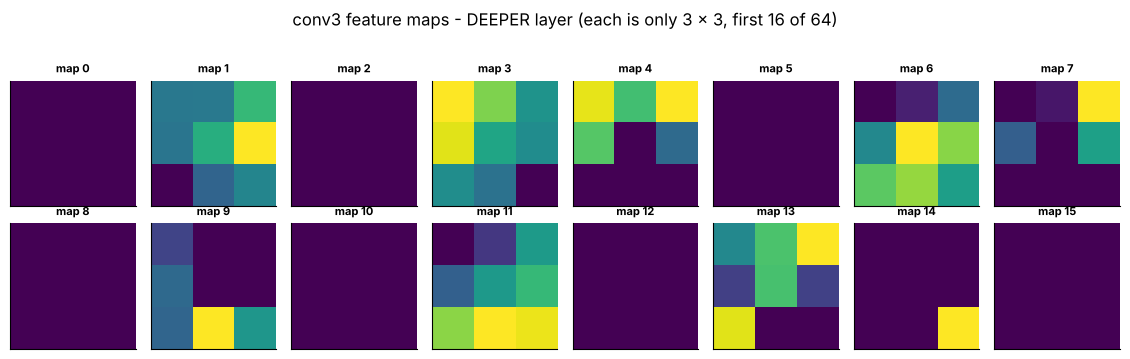

In [28]:
def show_maps(feature_maps, title, n=16):
    """feature_maps has shape (H, W, n_maps). Draw the first n maps, each on its own colour scale."""
    n = min(n, feature_maps.shape[-1])
    fig, axes = plt.subplots(2, n // 2, figsize=(1.45 * n // 2 + 0.4, 3.5))
    for k, ax in enumerate(axes.ravel()):
        show_image(ax, feature_maps[:, :, k], f"map {k}", cmap="viridis")
        ax.title.set_fontsize(8)
    fig.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(2.4, 2.6)); show_image(ax, probe, "Input image (28 x 28)"); plt.show()
show_maps(probe_outputs[0][0], f"conv1 feature maps - EARLY layer (each is {probe_outputs[0].shape[1]} x {probe_outputs[0].shape[2]}, first 16 of {probe_outputs[0].shape[3]})")
show_maps(probe_outputs[2][0], f"conv2 feature maps - MIDDLE layer (each is {probe_outputs[2].shape[1]} x {probe_outputs[2].shape[2]}, first 16 of {probe_outputs[2].shape[3]})")
show_maps(probe_outputs[4][0], f"conv3 feature maps - DEEPER layer (each is only {probe_outputs[4].shape[1]} x {probe_outputs[4].shape[2]}, first 16 of {probe_outputs[4].shape[3]})")

**Interpretation.**

* **[OBSERVED]** The early maps (`conv1`) are still large and look like *filtered versions of the boot*: some highlight outlines, some highlight bright regions, some are mostly dark (filters that barely responded to this image), and a few show a flat background level (a filter whose bias keeps an "empty" region above zero).
* **[OBSERVED]** The middle maps (`conv2`) are smaller and look more abstract. The deeper maps (`conv3`) are only **3 × 3** — too small to "look like" anything. At this depth, a map is better thought of as *"how strongly does this learned pattern appear in each of 9 broad regions?"*.
* **[OBSERVED]** Many values are exactly 0. That is ReLU at work: a filter that does not match anything in a region stays silent.
* **[INTUITION, with the caveat from Part 4]** Moving deeper, the network looks at larger parts of the image per number (each `conv3` value is influenced by a much bigger patch of the original image than each `conv1` value), so deeper maps tend to describe bigger, more combined structures. We cannot read a human concept like "heel" or "toe" from these pictures, and we should not pretend to.

**Limitations to remember.** (1) Feature maps for *one* image are an anecdote, not a proof of what the network "knows". (2) Visualisations show **what is computed**, not **why it helps** the prediction. (3) A different seed or architecture gives different filters and maps.

---
# Part 6 · CNN features as a feature vector → scikit-learn

So far the CNN predicted classes by itself. In **feature engineering** we often want something else: a **table of numbers** (one row per image) that *any* classic ML model can use. That is exactly what the CNN can give us if we stop *before* its final prediction layer.

```
Image            Convolutional layers          Feature maps        Global average        Feature vector        Classic ML
28 x 28 x 1  ->  conv1, pool1, conv2,      ->   3 x 3 x 64     ->   pooling (gap)    ->   64 numbers      ->   scikit-learn
                 pool2, conv3                  (64 small maps)     1 number per map      per image            (LogisticRegression, SVC, ...)
```

## Global average pooling in one tiny example
`conv3` ends with 64 feature maps, each 3×3. **Global average pooling (GAP)** replaces each whole map by **its average** — one number per map. Result: 64 maps → a vector of 64 numbers, no matter how large the image or the maps were.

Two maps of size 2×2 become a 2-number vector:
```
 map A: [[1, 3],      average = (1+3+5+7)/4 = 4.0
         [5, 7]]
 map B: [[0, 0],      average = (0+0+0+8)/4 = 2.0          feature vector = [4.0, 2.0]
         [0, 8]]
```
**Intuition [INTUITION]:** each of the 64 numbers says *"on average, how strongly is this learned pattern present anywhere in the image?"*. We lose *where* the pattern was; we keep *how much* of it there is.

In [29]:
# Cut the CNN just before its last layer: image in -> 64-number vector out.
extractor = keras.Model(inputs=cnn.inputs, outputs=cnn.get_layer("gap").output, name="feature_extractor")

# Every shape below is read from the model itself (nothing is typed in by hand).
print("input  shape (per image):", tuple(extractor.inputs[0].shape[1:]))
print("conv3  shape (per image):", tuple(cnn.get_layer("conv3").output.shape[1:]), " <- 64 feature maps of size 3 x 3")
print("output shape (per image):", tuple(extractor.output.shape[1:]), " <- the feature vector")

# Prove that GAP really is "the average of every feature map".
conv3_model = keras.Model(cnn.inputs, cnn.get_layer("conv3").output)
five = x_test[:5, ..., None]
maps = conv3_model.predict(five, verbose=0)                    # (5, 3, 3, 64)
by_hand = maps.mean(axis=(1, 2))                               # average over height and width -> (5, 64)
vectors = extractor.predict(five, verbose=0)                   # (5, 64)
assert np.allclose(by_hand, vectors, atol=1e-5)
print(f"\nmaps {maps.shape} --average over the 3 x 3 grid--> {by_hand.shape}: identical to the extractor's output. GAP = per-map average.")

input  shape (per image): (28, 28, 1)
conv3  shape (per image): (3, 3, 64)  <- 64 feature maps of size 3 x 3
output shape (per image): (64,)  <- the feature vector



maps (5, 3, 3, 64) --average over the 3 x 3 grid--> (5, 64): identical to the extractor's output. GAP = per-map average.


**Interpretation [OBSERVED].** The extractor turns a `28 × 28` picture into a vector with `64` numbers. We checked by hand that the vector is just the average of each `3 × 3` feature map.

## Extract features for the classifier's data
We run the extractor on `x_clf` (5,000 images the CNN **never trained on**) and on the 10,000 test images. The result is an ordinary table, just like a spreadsheet of tabular features:

In [30]:
t0 = time.time()
cnn_train = extractor.predict(x_clf[..., None],  verbose=0)       # (5000, 64)
cnn_test  = extractor.predict(x_test[..., None], verbose=0)       # (10000, 64)
cnn_secs = time.time() - t0
print(f"CNN feature matrices: train {cnn_train.shape}, test {cnn_test.shape}  (extracted in {cnn_secs:.1f} s)")
print(f"Compare: raw pixels had {raw_train.shape[1]} columns, HOG had {hog_train.shape[1]}, the CNN feature vector has {cnn_train.shape[1]}.\n")

np.set_printoptions(precision=2, suppress=True, linewidth=110)
print("First image of x_clf =", CLASS_NAMES[y_clf[0]], "-> first 10 of its 64 numbers:")
print(cnn_train[0, :10])
print("\nSummary over all 5,000 training vectors:  min = %.2f   max = %.2f   share of exact zeros = %.1f%%"
      % (cnn_train.min(), cnn_train.max(), 100 * (cnn_train == 0).mean()))

CNN feature matrices: train (5000, 64), test (10000, 64)  (extracted in 1.6 s)
Compare: raw pixels had 784 columns, HOG had 1296, the CNN feature vector has 64.

First image of x_clf = Dress -> first 10 of its 64 numbers:
[0.   5.12 0.   1.55 2.57 0.   0.24 0.61 3.2  0.81]

Summary over all 5,000 training vectors:  min = 0.00   max = 13.86   share of exact zeros = 32.4%


**Interpretation [OBSERVED].** Each image is now described by 64 non-negative numbers (they are averages of ReLU outputs, so they cannot be negative). Single numbers like `0.37` are not human-readable — "feature 7 = 0.37" does not mean anything by itself. What matters is whether **the pattern across all 64 numbers differs between classes**. Let us look at that.

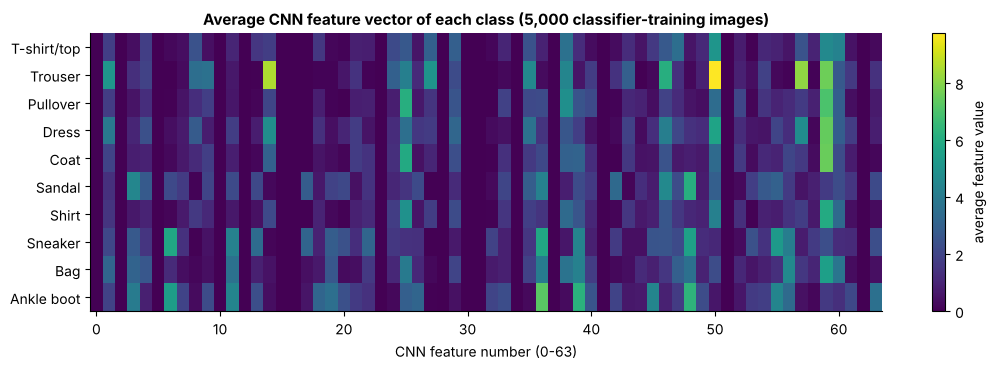

Distance between class-average vectors:  Sneaker vs Ankle boot = 7.69   Sneaker vs Trouser = 23.87


In [31]:
class_means = np.array([cnn_train[y_clf == k].mean(axis=0) for k in range(10)])     # (10 classes, 64 features)

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(class_means, aspect="auto", cmap="viridis")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("CNN feature number (0-63)"); ax.set_title("Average CNN feature vector of each class (5,000 classifier-training images)")
fig.colorbar(im, ax=ax, label="average feature value"); plt.tight_layout(); plt.show()

# How different are classes from each other, versus images inside one class?
a = class_means[CLASS_NAMES.index("Sneaker")]; b = class_means[CLASS_NAMES.index("Ankle boot")]; c = class_means[CLASS_NAMES.index("Trouser")]
print(f"Distance between class-average vectors:  Sneaker vs Ankle boot = {np.linalg.norm(a-b):.2f}   Sneaker vs Trouser = {np.linalg.norm(a-c):.2f}")

**Interpretation.**

* **[OBSERVED]** The rows of the heat-map are visibly different patterns: each class has its own "signature" across the 64 features, and classes that look alike (for example Sneaker and Ankle boot — both footwear) have more similar rows than very different ones (Sneaker vs Trouser), as the printed distances show.
* **[INTERPRETATION]** This is why a simple classifier can work on top of these features: the information it needs is already organised in the vector. We still cannot say *what* each of the 64 features "means" in human words.

## Train a scikit-learn classifier on the CNN features
Same recipe as before — same 5,000 images, same `StandardScaler + LogisticRegression`, same 10,000 test images. **Only the features change.** This is what makes the comparison fair.

In [32]:
acc_cnn_feat, _, secs = fit_and_score(cnn_train, cnn_test)
print(f"CNN features (64) + Logistic Regression -> test accuracy = {acc_cnn_feat:.3f}  (classifier trained in {secs:.1f} s)")
print(f"For reference (same classifier, same images): raw pixels = {acc_raw:.3f} | HOG = {acc_hog:.3f}")

# The features are not tied to logistic regression: any scikit-learn model can use them.
svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=3))
svm_model.fit(cnn_train, y_clf)
acc_cnn_svm = svm_model.score(cnn_test, y_test)
print(f"CNN features (64) + SVM (RBF kernel)    -> test accuracy = {acc_cnn_svm:.3f}")

CNN features (64) + Logistic Regression -> test accuracy = 0.873  (classifier trained in 1.8 s)
For reference (same classifier, same images): raw pixels = 0.793 | HOG = 0.815


CNN features (64) + SVM (RBF kernel)    -> test accuracy = 0.876


**Interpretation [OBSERVED].** In this run, a simple linear classifier on 64 learned numbers did better than on the 784 raw pixels, and also better than HOG (compare the three printed numbers). The same vectors also work with an SVM — the feature vector is a plain table, so it plugs into any scikit-learn model.

**Fair-play caveat.** The CNN's filters were trained with **30,000 labelled images**, while HOG needed *no* training. So the CNN features are not "free": they were paid for with labelled data and compute. We discuss this honestly in Part 7.

## A control experiment: the same architecture *without* training
Is it the **architecture** or the **training** that makes the features useful? We build a new network with the same layers but **random, untrained** filters, extract its 64-number vectors, and give them to the same classifier.

> This is a *control experiment*. Untrained random filters are **not** a learned representation. We include them only to measure how much of the benefit comes from training.

In [33]:
untrained = build_cnn(seed=SEED + 1)                                   # same layers, random starting weights, NEVER trained
untrained_extractor = keras.Model(untrained.inputs, untrained.get_layer("gap").output)
rand_train = untrained_extractor.predict(x_clf[..., None],  verbose=0)
rand_test  = untrained_extractor.predict(x_test[..., None], verbose=0)

acc_untrained, _, _ = fit_and_score(rand_train, rand_test)
print(f"Untrained (random-filter) CNN features + LogReg -> test accuracy = {acc_untrained:.3f}")
print(f"Trained CNN features              + LogReg -> test accuracy = {acc_cnn_feat:.3f}")
print(f"Improvement attributable to training: {acc_cnn_feat - acc_untrained:+.3f}")

Untrained (random-filter) CNN features + LogReg -> test accuracy = 0.775
Trained CNN features              + LogReg -> test accuracy = 0.873
Improvement attributable to training: +0.098


**Interpretation.**

* **[OBSERVED]** Random-filter features are not useless — a random convolution still computes *some* local summaries, and pooling keeps them — but the trained features are clearly better. The gap is the contribution of **training**.
* **[INTERPRETATION]** This supports the central message: the benefit comes from parameters that were **adjusted by the training process to suit the task**, not from the layer diagram alone.

## Making the extractor reusable (a taste of MLOps)
A feature extractor is an *artifact*: it must be **saved, versioned, reloaded and checked** — otherwise the features in production would silently differ from those used in training (training–serving skew). We save to a temporary folder and prove that the reloaded extractor gives the same numbers.

In [34]:
with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "feature_extractor.keras")
    extractor.save(path)                                               # architecture + trained weights in one file
    reloaded = keras.models.load_model(path)
    size_kb = os.path.getsize(path) / 1024
    same = np.allclose(reloaded.predict(x_test[:200, ..., None], verbose=0), cnn_test[:200], atol=1e-5)

print(f"Saved file size: {size_kb:.0f} KB | reloaded extractor gives identical features on 200 test images: {same}")
assert same

Saved file size: 119 KB | reloaded extractor gives identical features on 200 test images: True


**Interpretation [OBSERVED].** The whole extractor is one small file, and a reloaded copy reproduces the features exactly. In a real project this file would live in a **model registry** next to the exact code, data version and scikit-learn classifier that were trained with it (Part 10).

---
# Part 7 · Handcrafted vs CNN features — an honest comparison

## The comparison table

| Question | Raw pixels | Handcrafted (e.g. HOG) | CNN-learned features |
|---|---|---|---|
| **How are features obtained?** | Just flatten the image | A fixed recipe (gradients → cell histograms → normalisation) | A trained network; its filters are **parameters adjusted by training** |
| **Who decides the "rules"?** | Nobody | The **engineer**, in advance | **Training** (data + loss + optimizer), within the architecture the engineer chose |
| **Labelled data needed to build the extractor** | None | None (only for the classifier) | Yes — typically a lot (or reuse a network trained by someone else) |
| **Compute to build the extractor** | None | Very low | Moderate to very high (we used about a minute on CPU for a tiny CNN) |
| **Interpretability** | Easy to see, hard to use | High — you can explain every number | Lower — individual features rarely have a clean human meaning |
| **Flexibility across tasks** | Low | Task-specific design; new problem → new recipe | High — the same method adapts to new data; a trained extractor can be reused (*transfer learning*) |
| **Typical applications** | Quick baselines | Small data, tight compute budgets, embedded devices, when explainability matters | Large image collections, complex visual variation, retrieval, detection, medical/industrial vision |

> **Not a contest with a fixed winner.** Handcrafted features are still useful. A CNN is *not* always better: it needs data, compute and careful validation, and its failures are harder to explain.

## Measure it, on the same footing
All three feature types below use the **same** classifier (`StandardScaler + LogisticRegression`), the **same** 5,000 classifier-training images and the **same** 10,000 test images.

Feature type                # features   test accuracy
Raw pixels                         784           0.793
HOG (handcrafted)                1,296           0.815
CNN, untrained (control)            64           0.775
CNN, trained features               64           0.873


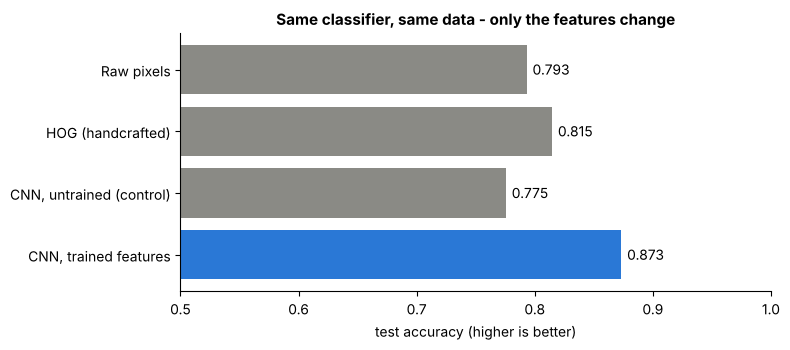

In [35]:
rows = [
    ("Raw pixels",              raw_train.shape[1], acc_raw),
    ("HOG (handcrafted)",       hog_train.shape[1], acc_hog),
    ("CNN, untrained (control)", rand_train.shape[1], acc_untrained),
    ("CNN, trained features",   cnn_train.shape[1], acc_cnn_feat),
]
print(f"{'Feature type':<26}{'# features':>12}{'test accuracy':>16}")
for name, dim, acc in rows:
    print(f"{name:<26}{dim:>12,}{acc:>16.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
names = [r[0] for r in rows]; accs = [r[2] for r in rows]
colors = [GREY, GREY, GREY, BLUE]
bars = ax.barh(names[::-1], accs[::-1], color=colors[::-1])
for b, a in zip(bars, accs[::-1]):
    ax.text(a + 0.005, b.get_y() + b.get_height() / 2, f"{a:.3f}", va="center")
ax.set_xlim(0.5, 1.0); ax.set_xlabel("test accuracy (higher is better)")
ax.set_title("Same classifier, same data - only the features change"); plt.tight_layout(); plt.show()

**Interpretation [OBSERVED].** The trained CNN features give the best accuracy here, with only 64 numbers per image. The untrained control is clearly worse than the trained one, so training mattered.

**Do not over-read this.** It is one dataset (small, centred, grayscale), one tiny CNN, one HOG setting, one classifier. A better-tuned HOG, or a different problem, would change the gaps. What the experiment *does* show is the mechanism: features that were adjusted by training for this task can be compact and effective.

## What if the classifier only has a few labelled examples?
A common practical question: *"I only have a handful of labelled images for my own classifier — which features help?"* We shrink the classifier's training set and re-measure. (The CNN extractor itself was already trained on 30,000 labelled images, so this tests **reuse of an extractor**, not training a CNN from scratch on a few images.)

classifier training images        100      500     1000     5000
Raw pixels                      0.677    0.765    0.784    0.793
HOG                             0.677    0.795    0.804    0.815
CNN features                    0.777    0.852    0.861    0.873


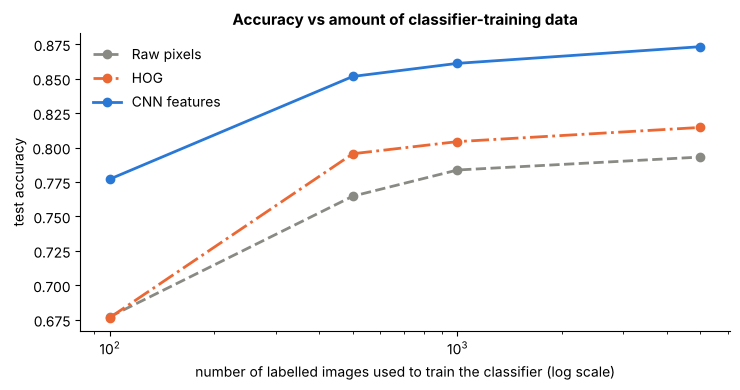

In [36]:
sizes = [100, 500, 1000, 5000]
curve = {"Raw pixels": [], "HOG": [], "CNN features": []}
for n in sizes:
    for label, (ftr, fte) in {"Raw pixels": (raw_train, raw_test), "HOG": (hog_train, hog_test), "CNN features": (cnn_train, cnn_test)}.items():
        acc, _, _ = fit_and_score(ftr[:n], fte, y_train=y_clf[:n])
        curve[label].append(acc)

print(f"{'classifier training images':<28}" + "".join(f"{n:>9}" for n in sizes))
for label, vals in curve.items():
    print(f"{label:<28}" + "".join(f"{v:>9.3f}" for v in vals))

fig, ax = plt.subplots(figsize=(7.5, 4))
for (label, vals), color, style in zip(curve.items(), [GREY, ORANGE, BLUE], ["--", "-.", "-"]):
    ax.plot(sizes, vals, style, color=color, lw=2, marker="o", label=label)
ax.set_xscale("log"); ax.set_xlabel("number of labelled images used to train the classifier (log scale)")
ax.set_ylabel("test accuracy"); ax.set_title("Accuracy vs amount of classifier-training data"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.**

* **[OBSERVED]** With very few labelled images, the 64-number CNN vectors usually hold up better than the long raw-pixel or HOG vectors. Short, informative vectors are easier for a classifier to fit from few examples. Look at your own table for the exact numbers.
* **[INTERPRETATION]** This is the idea behind **transfer learning**: train (or download) a good feature extractor once, then train small classifiers on top of it for many tasks.
* **Caveat.** The extractor learned from 30,000 labelled images of the *same kind* of pictures. If your new pictures look very different from the extractor's training pictures, the advantage can shrink or vanish — you must validate on your own data.

## When would you still choose handcrafted features?
* You have **no labelled data** to train an extractor and no suitable pre-trained one.
* The device is tiny (a microcontroller) and every multiplication counts.
* You must **explain** every feature to an auditor or regulator.
* The problem has a known, simple physical signature (for example "count bright pixels above a threshold" in a controlled factory camera).

And often the best practical choice is *both*: a CNN embedding plus a few engineered business features (image size, capture time, device ID) in one table — the same "combine features" idea you already use for tabular data.

---
# Part 8 · Where CNN-based feature extraction is used in industry

The pattern is always the same:

```
camera / scanner / photo  ->  preprocessing  ->  CNN feature extractor  ->  vector  ->  downstream system  ->  decision / action
```

| # | Use case | Input image | What the network learns (high level) | How the representation is used |
|---|---|---|---|---|
| 1 | **Manufacturing defect detection** | Photo of a product on a conveyor (bottle cap, circuit board, fabric) | Training on examples of good and defective items adjusts filters toward visual differences that separate them — scratches, missing parts, texture changes | A classifier on the vector flags suspicious items; or the vector of a new item is compared with vectors of known-good items and large distances are flagged |
| 2 | **Healthcare image representations** *(within a validated clinical workflow)* | X-ray, CT slice, retinal photo, pathology slide | Training on labelled scans adjusts filters toward patterns associated with the labels in that dataset | Representations feed a model that **prioritises** studies or **assists** a clinician. A qualified human reviews the result |
| 3 | **Retail visual similarity and retrieval** | Product photo from a catalogue or a customer's phone | Training adjusts filters so that images of similar products produce similar vectors | Compute a vector per catalogue item once; for a new photo, find the nearest vectors → "similar items" |
| 4 | **Autonomous-driving scene representation** | Camera frames from vehicle cameras | Training on many road scenes adjusts filters toward patterns useful for tasks like lane, vehicle and pedestrian recognition | The representation is one input among many to detection, tracking and planning modules, alongside radar, maps and rules |

> **Important — an extractor is not an application.** A CNN that produces good vectors is one component. A production system also needs: data validation, a **versioned** model and data, monitoring for **drift** (the camera, lighting or patient population changes), thresholds chosen with business cost in mind, human review where errors are costly, logging, security, and — in healthcare and automotive — regulatory approval and clinical or safety validation. Passing a benchmark is the start, not the end.

## A hands-on mini version: "find similar items" (use case 3)
We use the 64-number vectors as an **image search index**. For a query image, we find the images whose vectors are closest (by cosine similarity: do the two vectors point in the same direction?). To keep this honest we measure it: *of the 5 nearest neighbours, how many are in the same class as the query?* (called **precision@5**). We compare raw pixels with CNN vectors.

Precision@5 with raw-pixel vectors (784 numbers): 0.790
Precision@5 with CNN vectors        (64 numbers): 0.843


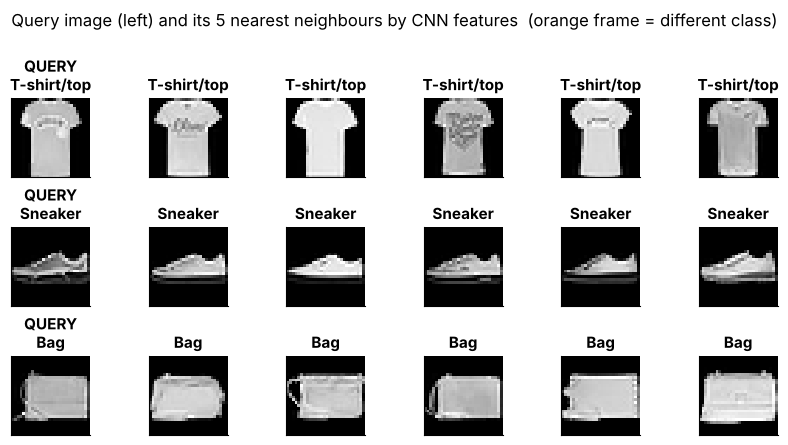

In [37]:
from sklearn.neighbors import NearestNeighbors

def precision_at_5(gallery, labels, n_queries=1000):
    """For the first n_queries images, find their 5 nearest neighbours in the gallery (excluding the image itself)."""
    nn = NearestNeighbors(n_neighbors=6, metric="cosine", algorithm="brute").fit(gallery)
    _, idx = nn.kneighbors(gallery[:n_queries])
    idx = idx[:, 1:]                                                  # drop column 0: each image is its own nearest neighbour
    return float((labels[idx] == labels[:n_queries, None]).mean()), idx

p_raw, _       = precision_at_5(raw_test, y_test)
p_cnn, idx_cnn = precision_at_5(cnn_test, y_test)
print(f"Precision@5 with raw-pixel vectors (784 numbers): {p_raw:.3f}")
print(f"Precision@5 with CNN vectors        (64 numbers): {p_cnn:.3f}")

# Show three queries and their 5 CNN-nearest neighbours.
queries = [int(np.where(y_test[:1000] == k)[0][0]) for k in (0, 7, 8)]       # a T-shirt, a sneaker, a bag
fig, axes = plt.subplots(3, 6, figsize=(8.4, 4.4))
for r, q in enumerate(queries):
    show_image(axes[r, 0], x_test[q], f"QUERY\n{CLASS_NAMES[y_test[q]]}")
    for c, j in enumerate(idx_cnn[q], start=1):
        show_image(axes[r, c], x_test[j], f"{CLASS_NAMES[y_test[j]]}")
        if y_test[j] != y_test[q]:
            for s in axes[r, c].spines.values(): s.set_visible(True); s.set_color(ORANGE); s.set_linewidth(2.5)
fig.suptitle("Query image (left) and its 5 nearest neighbours by CNN features  (orange frame = different class)", y=1.0)
plt.tight_layout(); plt.show()

**Interpretation.**

* **[OBSERVED]** Using CNN vectors, a larger share of the nearest neighbours belong to the query's class than with raw pixels, even though the vectors are over 12× shorter. Orange frames, if any, are mistakes — usually between look-alike classes.
* **[INTERPRETATION]** This is the core of visual search in retail: store one short vector per product, search by distance. Real systems use far bigger networks trained on millions of product photos, and approximate-nearest-neighbour indexes for speed.
* **Limit.** "Same class" is a crude score; real shoppers care about colour, price, style and brand. The representation can only reflect what its training objective encouraged.

## Connecting the four use cases to the Feature Engineering mindset
In every case the engineering questions are the ones you already know from tabular data:

1. *What exactly is available at prediction time?* (**no leakage** — e.g. a defect label must never leak into the input.)
2. *Is training data representative of production data?* (**drift** — a new camera, a new scanner model, a different season.)
3. *How do we validate?* (a held-out test set that mimics production, per-class and per-subgroup metrics.)
4. *How do we version, deploy and monitor the extractor?* (Part 10.)

---
# Part 9 · Exercises

Six exercises, from easy to challenging. Each starter cell **runs as it is** (so the notebook never breaks), but it does not yet answer the question — **edit it**. Try before you look at the hints, and try the hints before the solutions in Part 11 (the very end of the notebook).

Variables you can reuse: `x_clf, y_clf, x_test, y_test`, `cnn`, `extractor`, `feature_model`, `conv2d_valid`, `show_image`, `fit_and_score`, `raw_train, raw_test, hog_train, hog_test, cnn_train, cnn_test`, `CLASS_NAMES`.

---
## Exercise 1 (easy) — Change a filter
Part 3 applied a vertical-edge filter to the sneaker. Create a **horizontal-edge** filter and apply it (with ReLU) to the same sneaker. Then try one more filter of your own.

* **Hint:** a vertical-edge filter compares left and right columns. A horizontal-edge filter should compare the *top* row with the *bottom* row.
* **Expected observation:** the horizontal-edge map should light up along the sole and the top edge of the shoe, and stay dark on vertical outlines.

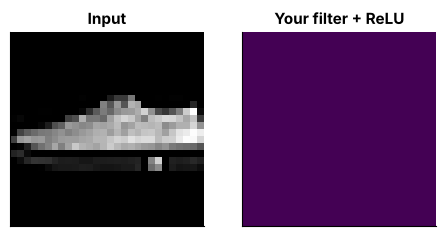

In [38]:
sneaker = x_clf[np.where(y_clf == 7)[0][0]]
my_filter = np.zeros((3, 3))            # TODO: replace with your own 3x3 numbers (positive on one side, negative on the opposite side)
my_map = np.maximum(conv2d_valid(sneaker, my_filter), 0)

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8))
show_image(axes[0], sneaker, "Input"); show_image(axes[1], my_map, "Your filter + ReLU", cmap="viridis")
plt.show()

---
## Exercise 2 (easy–medium) — Compare feature maps from two layers
Choose a **different** test image (for example a Trouser, class 1). Using `feature_model` from Part 5, get the outputs of `conv1` and `conv3`. For each, print the shape and the **share of values that are exactly zero**, and plot 8 maps.

* **Hint:** `feature_model.predict(image[None, ..., None])` returns a list ordered as `layer_names` = `["conv1","pool1","conv2","pool2","conv3"]`; `conv1` is item 0 and `conv3` is item 4.
* **Expected observation:** `conv1` maps are 26 × 26 and still resemble the image; `conv3` maps are only 3 × 3. Say what you **observe** (shapes, sparsity, appearance) separately from what you **suppose** (what the maps "mean").

In [39]:
other = x_test[np.where(y_test == 1)[0][0]]            # a Trouser
outputs = feature_model.predict(other[None, ..., None], verbose=0)
# TODO: print shape and zero-share for outputs[0] (conv1) and outputs[4] (conv3), then plot 8 maps of each
print(other.shape, [o.shape for o in outputs])

(28, 28) [(1, 26, 26, 16), (1, 13, 13, 16), (1, 11, 11, 32), (1, 5, 5, 32), (1, 3, 3, 64)]


---
## Exercise 3 (medium) — Extract one feature vector and inspect it
Take **one** image, run it through `extractor`, and print: the vector's **shape**, its **five largest values with their feature numbers**, and whether any value is negative. Explain *why* the answer to the last question is what it is.

* **Hint:** `np.argsort(vector)[::-1][:5]` gives the indices of the largest values. Remember the layer order: `conv3` has a ReLU, then global average pooling.
* **Expected observation:** shape `(64,)`; no negative values (an average of ReLU outputs cannot be negative).

In [40]:
image = x_test[0]
vector = extractor.predict(image[None, ..., None], verbose=0)[0]
# TODO: print vector.shape, the five largest values with their feature numbers, and whether vector.min() < 0
print(type(vector))

<class 'numpy.ndarray'>


---
## Exercise 4 (medium) — CNN features vs raw pixels with a different classifier
Use a **k-nearest-neighbours** classifier (`KNeighborsClassifier(n_neighbors=5)`, after a `StandardScaler`) trained on only the **first 2,000** images of `x_clf`. Compare **raw pixels (784)** with **CNN features (64)** on the 10,000 test images.

* **Hint:** `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))`. Slice with `raw_train[:2000]`, `cnn_train[:2000]`, `y_clf[:2000]`.
* **Expected observation:** the CNN features should give a higher accuracy and a much faster prediction. In 2–3 sentences, explain why distances between 64 learned numbers can be more meaningful than distances between 784 pixel values. (Part 1: a shifted image was far away in pixel space.)

In [41]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
# TODO: fit on raw_train[:2000] and cnn_train[:2000] separately, score on raw_test / cnn_test, and print both accuracies
print(knn)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])


---
## Exercise 5 (medium–hard) — A proper evaluation: baseline, accuracy and the most confusing pair
Train `LogisticRegression` (inside `StandardScaler`) on `cnn_train` and report: (a) the **majority-class baseline** accuracy, (b) the **raw-pixel** accuracy, (c) the **CNN-feature** accuracy, and (d) **which pair of classes is confused most often** by the CNN-feature classifier.

* **Hint:** `fit_and_score` returns `(accuracy, fitted_model, seconds)`. `sklearn.metrics.confusion_matrix(y_test, predictions)` has true classes in rows and predicted classes in columns; set its diagonal to 0 and find the largest remaining entry with `np.unravel_index(cm.argmax(), cm.shape)`.
* **Expected observation:** baseline ≈ 10%; CNN features clearly above raw pixels. The most confused pair should be two visually similar clothing items (such as Shirt with T-shirt/top). Is it a surprise? Would more *data* or better *features* fix it?

In [42]:
from sklearn.metrics import confusion_matrix
acc_c, model_c, _ = fit_and_score(cnn_train, cnn_test)
# TODO: compute the baseline, the raw accuracy (you already have acc_raw), the predictions model_c.predict(cnn_test), and the most confused pair
print(f"CNN-feature accuracy (given): {acc_c:.3f}")

CNN-feature accuracy (given): 0.873


---
## Exercise 6 (challenge) — Which layer makes the better feature vector?
We used global average pooling on `conv3` (64 numbers). Build a second extractor from **`conv2`** (32 numbers: add a `GlobalAveragePooling2D` layer after `conv2`). Train the same classifier and compare accuracy with the `conv3` features. Then write down a hypothesis for the difference — and say what extra experiment would test it.

* **Hint:** `x = layers.GlobalAveragePooling2D()(cnn.get_layer("conv2").output)` then `keras.Model(cnn.inputs, x)`.
* **Expected observation:** compare the two accuracies and decide whether the difference is small or large. (In our run the `conv2` features were noticeably worse — but check yours, and remember a single run is only one sample.) The point is to practise **choosing a layer as an experiment**, not to find "the" right layer.

In [43]:
# TODO: build extractor_conv2 and compute 32-number features for x_clf and x_test, then call fit_and_score
print("conv2 output shape per image:", tuple(cnn.get_layer("conv2").output.shape[1:]))

conv2 output shape per image: (11, 11, 32)


---
# Part 10 · Summary and knowledge check

## Concise recap

* An image is a **grid of numbers**. Raw pixels are a valid but awkward feature set: shifting an object changes many pixel values.
* **Handcrafted features** (like HOG) follow a recipe *we* write in advance; only the classifier is trained.
* A **CNN** is built from **filters** (small grids of weights) slid over the image to produce **feature maps**, followed by **ReLU** (keep positives) and **pooling** (shrink, keep strong responses).
* In **CNN-based feature learning**, **training** adjusts the network's parameters (loss → backpropagation → optimizer, repeated) so the resulting representations are useful for the task. We do not hand-write "detect an ear".
* Cutting off the last layer gives a **feature vector** (here 64 numbers after global average pooling) that any scikit-learn model can use.
* The comparison is not "CNN always wins": CNN features cost labelled data and compute and are harder to interpret; handcrafted features are cheap and explainable. Measure both on *your* problem.
* A CNN does **not** "understand" images like a human. It is a trained function that produces numeric representations.

## Knowledge check

### Multiple-choice questions
Think of your answer first; then click each answer to reveal it.

**Q1.** What is a *feature map*?
&nbsp;&nbsp;A. The list of class names  &nbsp;&nbsp;B. The output produced when one filter is slid over an image (or over another feature map)  &nbsp;&nbsp;C. The training dataset  &nbsp;&nbsp;D. The learning rate

<details><summary>Show answer</summary>

**B.** Each filter produces one feature map; a layer with 16 filters produces 16 feature maps. A is not related; C and D are not outputs of filters.
</details>

**Q2.** What is the key difference between HOG and a CNN's features?
&nbsp;&nbsp;A. HOG uses colours, CNNs do not  &nbsp;&nbsp;B. HOG's extraction recipe is fixed by the engineer; a CNN's filter values are adjusted by training  &nbsp;&nbsp;C. HOG is always more accurate  &nbsp;&nbsp;D. A CNN needs no data

<details><summary>Show answer</summary>

**B.** HOG's steps (gradients, cell histograms, normalisation) are specified in advance. In a CNN we choose the architecture, but the filter values come from training. C is false (it depends on the problem); D is false (training needs labelled data).
</details>

**Q3.** What does ReLU do?
&nbsp;&nbsp;A. Replaces negative values with 0 and keeps positive values  &nbsp;&nbsp;B. Makes the image larger  &nbsp;&nbsp;C. Computes the loss  &nbsp;&nbsp;D. Splits the data into train and test

<details><summary>Show answer</summary>

**A.** ReLU(x) = max(0, x). It adds the non-linearity that lets stacked layers represent more than a single linear filter could.
</details>

**Q4.** In our 64-number feature vector, what did global average pooling do?
&nbsp;&nbsp;A. Averaged each 3×3 feature map into a single number  &nbsp;&nbsp;B. Doubled the number of filters  &nbsp;&nbsp;C. Chose the best class  &nbsp;&nbsp;D. Removed the test set

<details><summary>Show answer</summary>

**A.** 64 maps of size 3×3 became 64 numbers (one average per map). The *where* information is dropped; the *how much* information is kept.
</details>

**Q5.** Why was the *untrained* network a useful control experiment?
&nbsp;&nbsp;A. It is the best model  &nbsp;&nbsp;B. It shows how much of the accuracy comes from training rather than from the architecture alone  &nbsp;&nbsp;C. It uses the test labels  &nbsp;&nbsp;D. It is faster to code

<details><summary>Show answer</summary>

**B.** Same layers, random filters: any gain of the trained version over it can be attributed to the training process. (It is a control, not a learned representation.)
</details>

### Short-answer questions

1. In your own words, explain the difference between *handcrafted feature extraction* and *CNN-based feature learning*. (3–4 sentences.)
2. A classmate says, "The filter in the first layer is an edge detector, so the CNN understands edges." What is wrong or too strong in that statement, and what evidence would you need?
3. Name two reasons why you might still prefer HOG over a CNN extractor for a particular project.

<details><summary>Show model answers</summary>

1. In handcrafted extraction the engineer specifies the recipe (for example gradients → cell histograms), and only the final classifier is trained. In CNN-based feature learning the engineer specifies the architecture, but the filter values are parameters adjusted by training (loss, backpropagation, optimizer) so the representation becomes useful for the task. The resulting vector can then be given to any classifier.
2. A picture of a filter shows numbers, not a meaning. It may *look* edge-like, but calling it an "edge detector" is an interpretation. And a CNN does not "understand" in the human sense — it computes numbers. Evidence: show which image patches activate it most, test how predictions change if the filter is switched off, and check several seeds.
3. Any two of: no labelled data to train an extractor; very limited compute or memory; need to explain each feature; the domain has a simple known signature; the new images are too different from any available pre-trained extractor's training data.
</details>

### Industry case-study question
*A factory photographs every bottle cap on a conveyor belt. Only 3% of caps are defective, and the company has 2,000 labelled defect photos. A manager proposes: "Train a CNN and let it decide." You are the ML engineer.*

Answer in 6–8 sentences: (a) what you would try first as a baseline, (b) what labelled data and validation you need and why accuracy alone can mislead here, (c) how the CNN extractor would be used with a classifier or an anomaly detector, and (d) what you would monitor after deployment.

<details><summary>Show model answer</summary>

(a) Start with a simple baseline — raw or HOG features with a plain classifier — to know what "good" looks like. (b) With 3% defects, a model that says "OK" always gets 97% accuracy, so use precision, recall and a confusion matrix, and a test set that mimics production (same camera, lighting, shifts); keep a held-out set that no tuning ever touches to avoid leakage. (c) Use a CNN (ideally pre-trained, then adapted) as an extractor and train a classifier on its vectors, or compare vectors of new caps with vectors of known-good caps and flag the large distances. (d) Monitor the input distribution and feature drift (new lighting, new camera, new batch of material), the defect rate and score distribution, and sample flagged items for human review; version the model, data and code so a retrain is reproducible. Choose the decision threshold using the cost of a missed defect versus a false alarm.
</details>

## The final recap: where CNN features sit in the Feature Engineering & MLOps lifecycle

```
Raw images -> Data validation -> FEATURE ENGINEERING / FEATURE LEARNING (this notebook) -> Model training
   -> Experiment tracking (parameters, metrics, artifacts) -> Model registry (versioned extractor + classifier)
   -> Deployment (API / batch job; the SAME extractor as in training) -> Monitoring (drift, accuracy, latency)
   -> Retraining -> back to deployment
```

* **Feature engineering → feature learning.** For images, the "feature engineering" step is replaced, or supplemented, by a *learned* extractor.
* **Training–serving consistency.** The extractor used at prediction time must be the *exact same file* (same weights, same preprocessing: divide by 255, same size) as the one used for training. Otherwise you get **training–serving skew**. Part 6 showed saving and reloading with a check.
* **Experiment tracking & registry.** Record the seed, architecture, epochs, data version and metrics (tools such as MLflow do this), and register the extractor and the classifier **together** as one versioned unit.
* **Feature stores.** Computed CNN vectors (embeddings) are often stored in a feature store or vector index so many models and applications reuse them.
* **Monitoring.** Cameras, scanners and customers change; the input images and the vectors **drift**. Watch for drift, then retrain on fresh labelled data.

**You can now explain the central idea in one sentence:** *with handcrafted features we write the extraction rules; with a CNN we choose an architecture and let training adjust its parameters so that the representation becomes useful — and then we treat that representation as a feature vector like any other, engineered, validated, versioned and monitored.*

---
# Appendix · Solutions to the exercises (optional — try first!)

Each solution is a normal code cell. Your numbers may differ slightly from ours.

### Solution 1 — a horizontal-edge filter
Rows matter now: the top row is negative, the bottom row is positive (a Sobel-style "horizontal edge" filter). Compare it with the vertical-edge filter from Part 3.

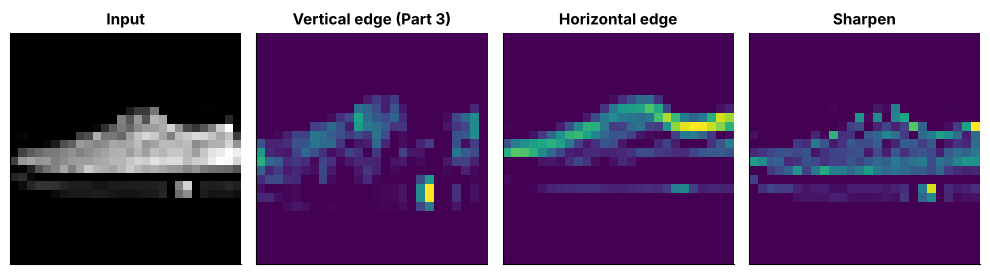

In [44]:
horizontal_edge = np.array([[-1, -2, -1],
                            [ 0,  0,  0],
                            [ 1,  2,  1]])
sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]])

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
show_image(axes[0], sneaker, "Input")
show_image(axes[1], np.maximum(conv2d_valid(sneaker, vertical_edge), 0), "Vertical edge (Part 3)", cmap="viridis")
show_image(axes[2], np.maximum(conv2d_valid(sneaker, horizontal_edge), 0), "Horizontal edge", cmap="viridis")
show_image(axes[3], np.maximum(conv2d_valid(sneaker, sharpen), 0), "Sharpen", cmap="viridis")
plt.tight_layout(); plt.show()

**Observation:** the horizontal-edge map highlights the sole and the top rim, the vertical-edge map highlights up-and-down outlines, and the sharpen filter keeps the picture but exaggerates local contrast. Same image, different filters, different feature maps.

### Solution 2 — conv1 vs conv3 on a Trouser

conv1: shape per image = (26, 26, 16), share of exact zeros = 49%
conv3: shape per image = (3, 3, 64), share of exact zeros = 64%


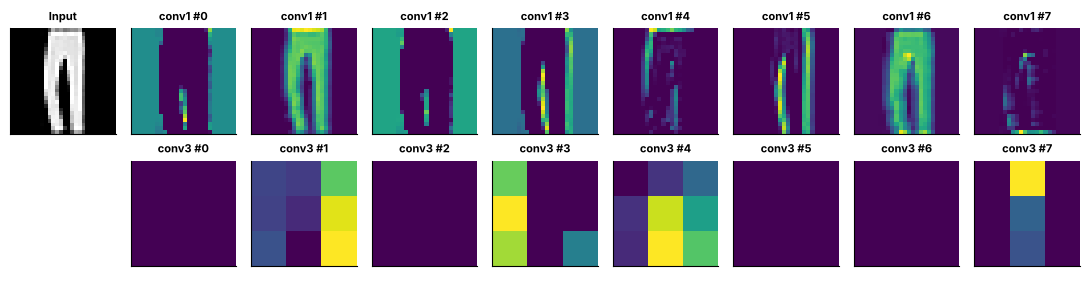

In [45]:
conv1_maps, conv3_maps = outputs[0][0], outputs[4][0]
for name, m in [("conv1", conv1_maps), ("conv3", conv3_maps)]:
    print(f"{name}: shape per image = {m.shape}, share of exact zeros = {(m == 0).mean():.0%}")

fig, axes = plt.subplots(2, 9, figsize=(11, 2.9))
show_image(axes[0, 0], other, "Input"); axes[1, 0].axis("off")
for k in range(8):
    show_image(axes[0, k + 1], conv1_maps[:, :, k], f"conv1 #{k}", cmap="viridis")
    show_image(axes[1, k + 1], conv3_maps[:, :, k], f"conv3 #{k}", cmap="viridis")
for ax in axes.ravel(): ax.title.set_fontsize(8)
plt.tight_layout(); plt.show()

**Observed:** `conv1` maps are 26×26 and resemble the trousers; `conv3` maps are 3×3 blocks, too small to look like anything. **Supposed (not proven):** deeper values summarise larger regions of the image. The fraction of zeros shows how selective each layer is for this particular image.

### Solution 3 — one feature vector

In [46]:
top5 = np.argsort(vector)[::-1][:5]
print("shape:", vector.shape)
print("five largest values (feature number: value):", {int(i): round(float(vector[i]), 2) for i in top5})
print("any negative value?", bool(vector.min() < 0), "| smallest value:", round(float(vector.min()), 3))

shape: (64,)
five largest values (feature number: value): {36: 7.76, 6: 5.93, 48: 5.84, 39: 5.05, 55: 4.77}
any negative value? False | smallest value: 0.0


**Why no negative values:** the last convolution is followed by ReLU (all outputs ≥ 0), and averaging non-negative numbers gives a non-negative number.

### Solution 4 — k-NN on raw pixels vs CNN features

In [47]:
t0 = time.time(); knn_raw = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(raw_train[:2000], y_clf[:2000]); acc_knn_raw = knn_raw.score(raw_test, y_test); t_raw = time.time() - t0
t0 = time.time(); knn_cnn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(cnn_train[:2000], y_clf[:2000]); acc_knn_cnn = knn_cnn.score(cnn_test, y_test); t_cnn = time.time() - t0
print(f"k-NN on raw pixels (784): accuracy {acc_knn_raw:.3f}  ({t_raw:.1f} s incl. scoring)")
print(f"k-NN on CNN features (64): accuracy {acc_knn_cnn:.3f}  ({t_cnn:.1f} s incl. scoring)")

k-NN on raw pixels (784): accuracy 0.781  (0.4 s incl. scoring)
k-NN on CNN features (64): accuracy 0.847  (0.1 s incl. scoring)


**Explanation:** k-NN relies on *distance*. In pixel space, a shifted or slightly different version of the same garment can be far away (Part 1), while a different garment can be nearer. The CNN vectors were produced by training so that images of the same class tend to produce similar vectors, so nearest neighbours are more often of the right class. With 64 columns instead of 784, distance calculations are also much cheaper.

### Solution 5 — baseline, raw, CNN and the most confusing pair

In [48]:
baseline = DummyClassifier(strategy="most_frequent").fit(cnn_train, y_clf).score(cnn_test, y_test)
print(f"(a) majority-class baseline: {baseline:.3f} | (b) raw pixels: {acc_raw:.3f} | (c) CNN features: {acc_c:.3f}")

cm = confusion_matrix(y_test, model_c.predict(cnn_test))
np.fill_diagonal(cm, 0)                                               # ignore correct predictions
true_k, pred_k = np.unravel_index(cm.argmax(), cm.shape)
print(f"(d) most frequent mistake: true '{CLASS_NAMES[true_k]}' predicted as '{CLASS_NAMES[pred_k]}' ({cm.max()} of the 10,000 test images)")

(a) majority-class baseline: 0.100 | (b) raw pixels: 0.793 | (c) CNN features: 0.873
(d) most frequent mistake: true 'Shirt' predicted as 'T-shirt/top' (173 of the 10,000 test images)


**Discussion:** the most common mistake involves two visually similar upper-body garments. Better features or more data can help, but some pairs are inherently ambiguous at 28 × 28 pixels, which is a reminder to look at *where* a model fails, not only at one accuracy number.

### Solution 6 — features from `conv2`

In [49]:
conv2_gap = layers.GlobalAveragePooling2D()(cnn.get_layer("conv2").output)
extractor_conv2 = keras.Model(cnn.inputs, conv2_gap)
c2_train = extractor_conv2.predict(x_clf[..., None],  verbose=0)
c2_test  = extractor_conv2.predict(x_test[..., None], verbose=0)
acc_c2, _, _ = fit_and_score(c2_train, c2_test)
print(f"conv2 features: {c2_train.shape[1]} numbers -> accuracy {acc_c2:.3f}   |   conv3 features: {cnn_train.shape[1]} numbers -> accuracy {acc_cnn_feat:.3f}")

conv2 features: 32 numbers -> accuracy 0.807   |   conv3 features: 64 numbers -> accuracy 0.873


**Discussion:** in our run the `conv2` vector (32 numbers) gave clearly lower accuracy than the `conv3` vector (64 numbers). A hypothesis: the CNN was trained end-to-end so that `conv3` (just before the classifier) is the layer pushed hardest to separate the classes, and it also has twice as many numbers. Two things are confounded here — *depth* and *vector size* — so we cannot say which one matters. To test it you would repeat with several seeds, report the mean and spread, try concatenating both vectors (96 numbers), and compare with a 32-number `conv3` subset. A single run is an anecdote, not a finding.

---
*End of notebook.*